In [1]:
import configparser
import json
import os
import re

import joblib
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
import shap
from venn import venn

In [2]:
os.chdir('../')

In [3]:
data = configparser.ConfigParser(interpolation=configparser.ExtendedInterpolation())
data.read('data.ini')
data = data['DEFAULT']

In [4]:
with open(data['ml'] + 'tools_features_selection.json', 'r') as file:
    features_selections = json.load(file)

features_selections_genes = {}
for key, value in features_selections.items():
    features_selections_genes[key] = value['genes']

# maxmif HN - onlyRAS_onlyNonRAS

In [5]:
key = 'maxmif HN - onlyRAS_onlyNonRAS'

## mutclust

In [6]:
suffix_tm = 'TCGA_tran&mut_["mutclust - ALL"]'
modelsDir_tm = f'{data['ml___models']}optimized_accuracy/{suffix_tm}'
inputDir_tm = f'{data['ml___input']}{suffix_tm}'

suffix_m = 'merged_mut_["mutclust - ALL"]'
modelsDir_m = f'{data['ml___models']}optimized_accuracy/{suffix_m}'
inputDir_m = f'{data['ml___input']}{suffix_m}'

In [7]:
scaler_tm = joblib.load(f'{modelsDir_tm}/[\"{key}\"]/scaler.joblib')
scaler_m = joblib.load(f'{modelsDir_m}/[\"{key}\"]/scaler.joblib')

with open(f'{modelsDir_tm}/[\"{key}\"]/features_info.json') as f:
    feature_tm = json.load(f)['valid_features_train']
with open(f'{modelsDir_m}/[\"{key}\"]/features_info.json') as f:
    feature_m = json.load(f)['valid_features_train']

scaler_tm = joblib.load(f'{modelsDir_tm}/[\"{key}\"]/scaler.joblib')
scaler_m = joblib.load(f'{modelsDir_m}/[\"{key}\"]/scaler.joblib')

train_RAS_tm = pd.read_csv(f'{inputDir_tm}/train_RAS.csv', sep=',', comment='#', engine='python')
train_nonRAS_tm = pd.read_csv(f'{inputDir_tm}/train_nonRAS.csv', sep=',', comment='#', engine='python')
test_RAS_tm = pd.read_csv(f'{inputDir_tm}/test_RAS.csv', sep=',', comment='#', engine='python')
test_nonRAS_tm = pd.read_csv(f'{inputDir_tm}/test_nonRAS.csv', sep=',', comment='#', engine='python')

train_RAS_m = pd.read_csv(f'{inputDir_m}/train_RAS.csv', sep='\t', comment='#', engine='python')
train_nonRAS_m = pd.read_csv(f'{inputDir_m}/train_nonRAS.csv', sep='\t', comment='#', engine='python')
test_RAS_m = pd.read_csv(f'{inputDir_m}/test_RAS.csv', sep='\t', comment='#', engine='python')
test_nonRAS_m = pd.read_csv(f'{inputDir_m}/test_nonRAS.csv', sep='\t', comment='#', engine='python')

train_tm = scaler_tm.transform(pd.concat([train_RAS_tm, train_nonRAS_tm])[feature_tm])
test_tm = scaler_tm.transform(pd.concat([test_RAS_tm, test_nonRAS_tm])[feature_tm])

train_m = scaler_m.transform(pd.concat([train_RAS_m, train_nonRAS_m])[feature_m])
test_m = scaler_m.transform(pd.concat([test_RAS_m, test_nonRAS_m])[feature_m])

In [8]:
len(feature_tm), len(feature_m), len(set(feature_tm) & set(feature_m))

(4689, 2751, 2650)

### logistic regression - mutclust

In [9]:
model_tm = joblib.load(f'{modelsDir_tm}/[\"{key}\"]/logisticRegression.joblib')
model_m = joblib.load(f'{modelsDir_m}/[\"{key}\"]/logisticRegression.joblib')

In [10]:
weights_tm = pd.DataFrame({'feature': feature_tm, 'weight': model_tm.coef_[0]}).sort_values('weight', ascending=False)
weights_m = pd.DataFrame({'feature': feature_m, 'weight': model_m.coef_[0]}).sort_values('weight', ascending=False)

weights_tm['gene'] = weights_tm['feature'].str.split('_').str[0]
weights_m['gene'] = weights_m['feature'].str.split('_').str[0]

weights_tm = weights_tm[['feature', 'gene', 'weight']]
weights_m = weights_m[['feature', 'gene', 'weight']]

# Normalize weights
weights_tm[['weight']] = weights_tm[['weight']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
weights_m[['weight']] = weights_m[['weight']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)

weights = pd.merge(weights_tm, weights_m, on=['feature', 'gene'], suffixes=('_tm', '_m'), how='inner')
weights['sum'] = weights['weight_tm'] + weights['weight_m']
weights[['sum']] = weights[['sum']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
weights = weights.sort_values('sum', ascending=False)

In [11]:
weights[(weights['weight_tm'] > 0) != (weights['weight_m'] > 0)]

,feature,gene,weight_tm,weight_m,sum
1469,KDM5C_noCluster,KDM5C,-0.040205,0.766985,0.421743
1486,DES_noCluster,DES,-0.043494,0.725828,0.395951
1396,ITIH3_noCluster,ITIH3,-0.031899,0.706062,0.391210
1616,GNL1_noCluster,GNL1,-0.061626,0.705874,0.373850
1769,DCPS_noCluster,DCPS,-0.082860,0.702251,0.359426
...,...,...,...,...,...
777,SLC25A22_noCluster,SLC25A22,0.050953,-0.595680,-0.316099
558,SEC61A2_noCluster,SEC61A2,0.087295,-0.671328,-0.338908
895,SPN_noCluster,SPN,0.032962,-0.618426,-0.339739
897,PDE5A_noCluster,PDE5A,0.032854,-0.690044,-0.381360


In [12]:
plot_tm = pd.DataFrame(
    [(i, len(weights_tm.loc[weights_tm['weight'] > i, 'feature'])) for i in np.arange(weights_tm['weight'].max(), weights_tm['weight'].min(), -0.001)],
    columns=['weight', 'numFeatures']
)
plot_m = pd.DataFrame(
    [(i, len(weights_m.loc[weights_m['weight'] > i, 'feature'])) for i in np.arange(weights_m['weight'].max(), weights_m['weight'].min(), -0.001)],
    columns=['weight', 'numFeatures']
)

Text(0.5, 1.0, 'mut')

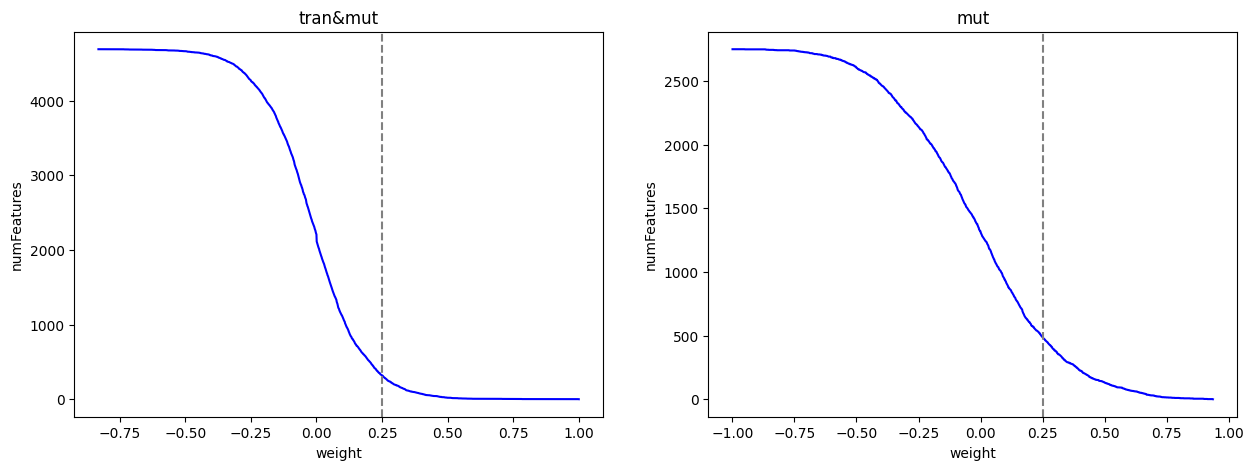

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax = ax.flatten()

ax[0].plot(plot_tm['weight'], plot_tm['numFeatures'], color='blue')
ax[0].axvline(x=0.25, color='grey', linestyle='--')
# ax[0].axvline(x=-0.25, color='grey', linestyle=':')
ax[0].set_xlabel('weight')
ax[0].set_ylabel('numFeatures')
ax[0].set_title('tran&mut')

ax[1].plot(plot_m['weight'], plot_m['numFeatures'], color='blue')
ax[1].axvline(x=0.25, color='grey', linestyle='--')
# ax[1].axvline(x=-0.40, color='grey', linestyle=':')
ax[1].set_xlabel('weight')
ax[1].set_ylabel('numFeatures')
ax[1].set_title('mut')

In [14]:
RAS_sF_tm = set(weights_tm.loc[weights_tm['weight'] > 0.25, 'feature'])
RAS_sF_tm = set([
    f for f in RAS_sF_tm 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])

RAS_sF_m = set(weights_m.loc[weights_m['weight'] > 0.25, 'feature'])

In [15]:
len(RAS_sF_tm), len(RAS_sF_m), len(RAS_sF_tm & RAS_sF_m)

(128, 487, 67)

In [16]:
weights[weights['feature'].isin(RAS_sF_tm & RAS_sF_m)]

,feature,gene,weight_tm,weight_m,sum
0,TFRC_noCluster,TFRC,1.000000,0.539881,0.893577
20,SNAP91_noCluster,SNAP91,0.432801,0.900469,0.773682
6,PDZD4_noCluster,PDZD4,0.514771,0.817937,0.773356
35,MACROD2_noCluster,MACROD2,0.389916,0.913467,0.756339
43,CRP_noCluster,CRP,0.359917,0.935735,0.751853
...,...,...,...,...,...
120,MINK1_noCluster,MINK1,0.259062,0.341376,0.348428
64,TUBB2A_noCluster,TUBB2A,0.323281,0.267424,0.342780
114,ST13_noCluster,ST13,0.262231,0.328208,0.342625
103,DOK2_noCluster,DOK2,0.269090,0.276994,0.316887


In [17]:
# remove suffic _noCluster and _\d+_\d+
RAS_sG_tm = set([re.sub(r'_noCluster|_\d+_\d+', '', f) for f in RAS_sF_tm])
RAS_sG_m = set([re.sub(r'_noCluster|_\d+_\d+', '', f) for f in RAS_sF_m])

In [18]:
len(RAS_sG_tm), len(RAS_sG_m), len(RAS_sG_tm & RAS_sG_m)

(128, 482, 68)

In [19]:
weights[weights['gene'].isin(RAS_sG_tm & RAS_sG_m)]

,feature,gene,weight_tm,weight_m,sum
0,TFRC_noCluster,TFRC,1.000000,0.539881,0.893577
20,SNAP91_noCluster,SNAP91,0.432801,0.900469,0.773682
6,PDZD4_noCluster,PDZD4,0.514771,0.817937,0.773356
35,MACROD2_noCluster,MACROD2,0.389916,0.913467,0.756339
43,CRP_noCluster,CRP,0.359917,0.935735,0.751853
...,...,...,...,...,...
973,TAGAP_709_716,TAGAP,0.020313,0.043200,0.036856
2287,POM121_noCluster,POM121,-0.196753,-0.077295,-0.159027
2446,OXSM_noCluster,OXSM,-0.260911,-0.223448,-0.281069
2588,MACROD2_322_334,MACROD2,-0.363928,-0.146102,-0.295965


In [20]:
'TNFSF11' in (RAS_sG_tm & RAS_sG_m)
weights[weights['gene'] == 'TNFSF11']

,feature,gene,weight_tm,weight_m,sum
27,TNFSF11_noCluster,TNFSF11,0.405871,0.519721,0.537111


In [21]:
RAS_sC_tm = set([
    f for f in RAS_sF_tm 
    if ('_noCluster' not in f)
])

RAS_sC_m = set([
    f for f in RAS_sF_m 
    if ('_noCluster' not in f)
])

In [22]:
len(RAS_sC_tm), len(RAS_sC_m), len(RAS_sC_tm & RAS_sC_m)

(8, 31, 4)

In [23]:
weights[weights['feature'].isin(RAS_sC_tm & RAS_sC_m)]

,feature,gene,weight_tm,weight_m,sum
18,POM121_1021_1050,POM121,0.442615,0.438743,0.511443
41,NFKBIZ_191_212,NFKBIZ,0.367913,0.447068,0.472925
33,RIMKLB_311_317,RIMKLB,0.390665,0.395628,0.456277
58,OXSM_177_178,OXSM,0.336704,0.397656,0.426141


Text(0.5, 1.0, 'Clusters')

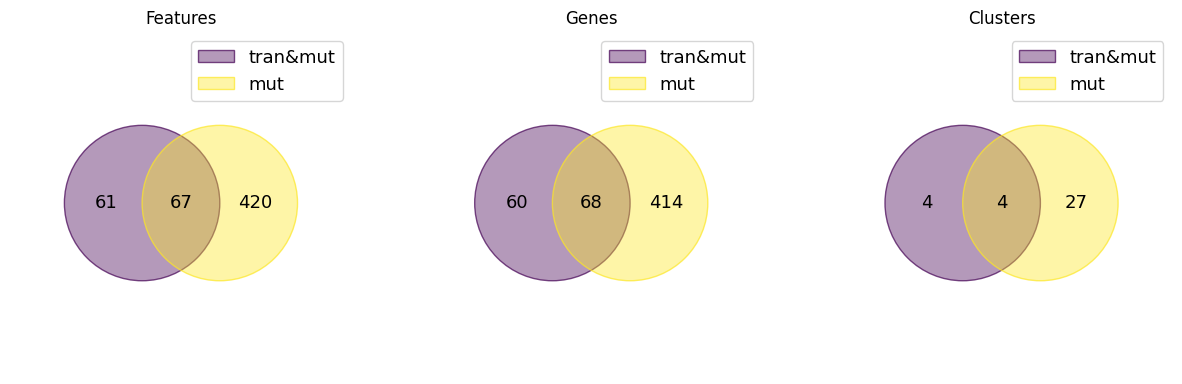

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

venn({
    'tran&mut': RAS_sF_tm,
    'mut': RAS_sF_m
}, ax=ax[0])
ax[0].set_title('Features')

venn({
    'tran&mut': RAS_sG_tm,
    'mut': RAS_sG_m
}, ax=ax[1])
ax[1].set_title('Genes')

venn({
    'tran&mut': RAS_sC_tm,
    'mut': RAS_sC_m
}, ax=ax[2])
ax[2].set_title('Clusters')

### linearSVM - mutclust

In [25]:
model_tm = joblib.load(f'{modelsDir_tm}/[\"{key}\"]/linearSVM.joblib')
model_m = joblib.load(f'{modelsDir_m}/[\"{key}\"]/linearSVM.joblib')

In [26]:
weights_tm = pd.DataFrame({'feature': feature_tm, 'weight': model_tm.coef_[0]}).sort_values('weight', ascending=False)
weights_m = pd.DataFrame({'feature': feature_m, 'weight': model_m.coef_[0]}).sort_values('weight', ascending=False)

weights_tm['gene'] = weights_tm['feature'].str.split('_').str[0]
weights_m['gene'] = weights_m['feature'].str.split('_').str[0]

weights_tm = weights_tm[['feature', 'gene', 'weight']]
weights_m = weights_m[['feature', 'gene', 'weight']]

# Normalize weights
weights_tm[['weight']] = weights_tm[['weight']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
weights_m[['weight']] = weights_m[['weight']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)

weights = pd.merge(weights_tm, weights_m, on=['feature', 'gene'], suffixes=('_tm', '_m'), how='inner')
weights['sum'] = weights['weight_tm'] + weights['weight_m']
weights[['sum']] = weights[['sum']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
weights = weights.sort_values('sum', ascending=False)

In [27]:
weights[(weights['weight_tm'] > 0) != (weights['weight_m'] > 0)]

,feature,gene,weight_tm,weight_m,sum
1326,DES_noCluster,DES,-0.009800,0.812405,0.470634
1668,RIMKLB_noCluster,RIMKLB,-0.058124,0.720937,0.388662
1315,SLC2A2_noCluster,SLC2A2,-0.008073,0.620895,0.359349
1540,ITIH3_noCluster,ITIH3,-0.041994,0.654241,0.359011
1350,RPS13_noCluster,RPS13,-0.013092,0.593657,0.340434
...,...,...,...,...,...
2634,KCNK2_noCluster,KCNK2,-0.576251,0.041096,-0.313805
842,SLC25A22_noCluster,SLC25A22,0.049304,-0.606577,-0.326775
1136,GGA2_noCluster,GGA2,0.000971,-0.591652,-0.346365
1113,TIMM44_noCluster,TIMM44,0.006261,-0.644063,-0.373996


In [28]:
plot_tm = pd.DataFrame(
    [(i, len(weights_tm.loc[weights_tm['weight'] > i, 'feature'])) for i in np.arange(weights_tm['weight'].max(), weights_tm['weight'].min(), -0.001)],
    columns=['weight', 'numFeatures']
)
plot_m = pd.DataFrame(
    [(i, len(weights_m.loc[weights_m['weight'] > i, 'feature'])) for i in np.arange(weights_m['weight'].max(), weights_m['weight'].min(), -0.001)],
    columns=['weight', 'numFeatures']
)

Text(0.5, 1.0, 'mut')

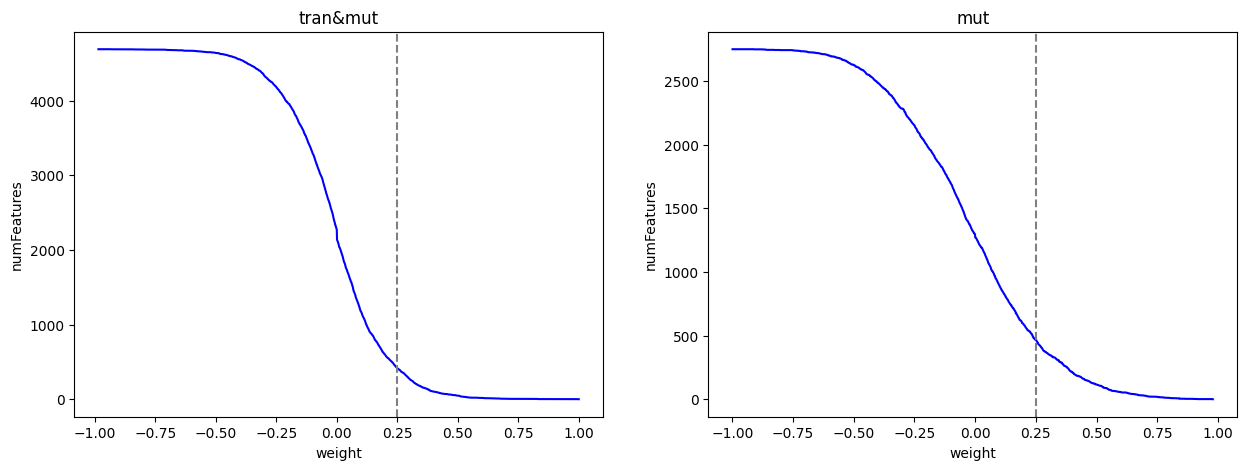

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax = ax.flatten()

ax[0].plot(plot_tm['weight'], plot_tm['numFeatures'], color='blue')
ax[0].axvline(x=0.25, color='grey', linestyle='--')
# ax[0].axvline(x=-0.25, color='grey', linestyle=':')
ax[0].set_xlabel('weight')
ax[0].set_ylabel('numFeatures')
ax[0].set_title('tran&mut')

ax[1].plot(plot_m['weight'], plot_m['numFeatures'], color='blue')
ax[1].axvline(x=0.25, color='grey', linestyle='--')
# ax[1].axvline(x=-0.40, color='grey', linestyle=':')
ax[1].set_xlabel('weight')
ax[1].set_ylabel('numFeatures')
ax[1].set_title('mut')

In [30]:
RAS_sF_tm = set(weights_tm.loc[weights_tm['weight'] > 0.25, 'feature'])
RAS_sF_tm = set([
    f for f in RAS_sF_tm 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])

RAS_sF_m = set(weights_m.loc[weights_m['weight'] > 0.25, 'feature'])

In [31]:
len(RAS_sF_tm), len(RAS_sF_m), len(RAS_sF_tm & RAS_sF_m)

(183, 466, 95)

In [32]:
weights[weights['feature'].isin(RAS_sF_tm & RAS_sF_m)]

,feature,gene,weight_tm,weight_m,sum
57,CRP_noCluster,CRP,0.382802,0.979275,0.798699
14,SNAP91_noCluster,SNAP91,0.524977,0.828578,0.793702
22,MACROD2_noCluster,MACROD2,0.506547,0.840630,0.789962
9,AASS_noCluster,AASS,0.543653,0.705029,0.732206
81,FIG4_noCluster,FIG4,0.344627,0.864067,0.708758
...,...,...,...,...,...
138,MINK1_noCluster,MINK1,0.290669,0.284528,0.337286
125,GNAT1_noCluster,GNAT1,0.297373,0.277361,0.337015
134,NEK4_noCluster,NEK4,0.294159,0.273128,0.332648
165,MIP_142_143,MIP,0.266472,0.276697,0.318505


In [33]:
# remove suffic _noCluster and _\d+_\d+
RAS_sG_tm = set([re.sub(r'_noCluster|_\d+_\d+', '', f) for f in RAS_sF_tm])
RAS_sG_m = set([re.sub(r'_noCluster|_\d+_\d+', '', f) for f in RAS_sF_m])

In [34]:
len(RAS_sG_tm), len(RAS_sG_m), len(RAS_sG_tm & RAS_sG_m)

(183, 462, 95)

In [35]:
weights[weights['gene'].isin(RAS_sG_tm & RAS_sG_m)]

,feature,gene,weight_tm,weight_m,sum
57,CRP_noCluster,CRP,0.382802,0.979275,0.798699
14,SNAP91_noCluster,SNAP91,0.524977,0.828578,0.793702
22,MACROD2_noCluster,MACROD2,0.506547,0.840630,0.789962
9,AASS_noCluster,AASS,0.543653,0.705029,0.732206
81,FIG4_noCluster,FIG4,0.344627,0.864067,0.708758
...,...,...,...,...,...
2259,POM121_noCluster,POM121,-0.203287,-0.125398,-0.192736
2462,OXSM_noCluster,OXSM,-0.303768,-0.182156,-0.284938
2590,ACTL6B_noCluster,ACTL6B,-0.423003,-0.190850,-0.359953
2605,MACROD2_322_334,MACROD2,-0.449375,-0.193516,-0.376981


In [36]:
'TNFSF11' in (RAS_sG_tm & RAS_sG_m)
weights[weights['gene'] == 'TNFSF11']

,feature,gene,weight_tm,weight_m,sum
30,TNFSF11_noCluster,TNFSF11,0.459192,0.374799,0.489038


In [37]:
RAS_sC_tm = set([
    f for f in RAS_sF_tm 
    if ('_noCluster' not in f)
])

RAS_sC_m = set([
    f for f in RAS_sF_m 
    if ('_noCluster' not in f)
])

In [38]:
len(RAS_sC_tm), len(RAS_sC_m), len(RAS_sC_tm & RAS_sC_m)

(12, 28, 6)

In [39]:
weights[weights['feature'].isin(RAS_sC_tm & RAS_sC_m)]

,feature,gene,weight_tm,weight_m,sum
21,POM121_1021_1050,POM121,0.507350,0.422265,0.545110
40,OXSM_177_178,OXSM,0.422342,0.429257,0.499363
43,RIMKLB_311_317,RIMKLB,0.415404,0.365599,0.457967
147,ACTL6B_45_50,ACTL6B,0.283992,0.488019,0.452694
42,NFKBIZ_191_212,NFKBIZ,0.416712,0.281050,0.409156
165,MIP_142_143,MIP,0.266472,0.276697,0.318505


Text(0.5, 1.0, 'Clusters')

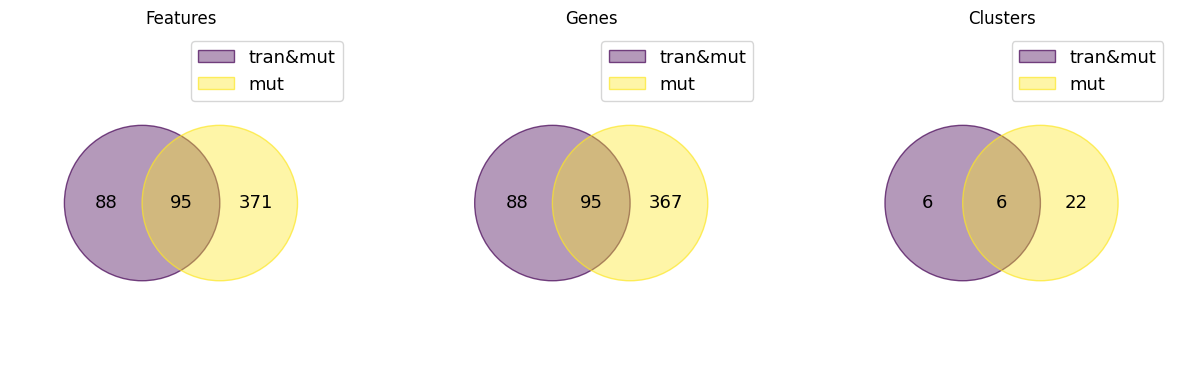

In [40]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

venn({
    'tran&mut': RAS_sF_tm,
    'mut': RAS_sF_m
}, ax=ax[0])
ax[0].set_title('Features')

venn({
    'tran&mut': RAS_sG_tm,
    'mut': RAS_sG_m
}, ax=ax[1])
ax[1].set_title('Genes')

venn({
    'tran&mut': RAS_sC_tm,
    'mut': RAS_sC_m
}, ax=ax[2])
ax[2].set_title('Clusters')

### logistic regression lasso - mutclust

In [41]:
model_tm = joblib.load(f'{modelsDir_tm}/[\"{key}\"]/logisticRegressionLasso.joblib')
model_m = joblib.load(f'{modelsDir_m}/[\"{key}\"]/logisticRegressionLasso.joblib')

In [42]:
weights_tm = pd.DataFrame({'feature': feature_tm, 'weight': model_tm.coef_[0]}).sort_values('weight', ascending=False)
weights_m = pd.DataFrame({'feature': feature_m, 'weight': model_m.coef_[0]}).sort_values('weight', ascending=False)

weights_tm['gene'] = weights_tm['feature'].str.split('_').str[0]
weights_m['gene'] = weights_m['feature'].str.split('_').str[0]

weights_tm = weights_tm[['feature', 'gene', 'weight']]
weights_m = weights_m[['feature', 'gene', 'weight']]

# Normalize weights
weights_tm[['weight']] = weights_tm[['weight']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
weights_m[['weight']] = weights_m[['weight']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)

weights = pd.merge(weights_tm, weights_m, on=['feature', 'gene'], suffixes=('_tm', '_m'), how='inner')
weights['sum'] = weights['weight_tm'] + weights['weight_m']
weights[['sum']] = weights[['sum']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
weights = weights.sort_values('sum', ascending=False)

In [43]:
weights_m[weights_m['weight'] != 0]

,feature,gene,weight
0,A1CF_noCluster,A1CF,NaN
1837,PQLC2_233_234,PQLC2,NaN
1829,PPP2R3B_noCluster,PPP2R3B,NaN
1830,PPP2R5A_noCluster,PPP2R5A,NaN
1831,PPP2R5C_noCluster,PPP2R5C,NaN
...,...,...,...
918,GOLGA2_noCluster,GOLGA2,NaN
919,GOLGA4_noCluster,GOLGA4,NaN
920,GOLGA5_noCluster,GOLGA5,NaN
921,GOLPH3_noCluster,GOLPH3,NaN


In [44]:
sum(model_m.coef_[0])

0.0

model with only mutational data has all weights as zero

## oncodriveclustl

In [45]:
suffix_tm = 'TCGA_tran&mut_["oncodriveclustl_coadreadParams - ALL"]'
modelsDir_tm = f'{data['ml___models']}optimized_accuracy/{suffix_tm}'
inputDir_tm = f'{data['ml___input']}{suffix_tm}'

suffix_m = 'merged_mut_["oncodriveclustl_coadreadParams - ALL"]'
modelsDir_m = f'{data['ml___models']}optimized_accuracy/{suffix_m}'
inputDir_m = f'{data['ml___input']}{suffix_m}'

In [46]:
scaler_tm = joblib.load(f'{modelsDir_tm}/[\"{key}\"]/scaler.joblib')
scaler_m = joblib.load(f'{modelsDir_m}/[\"{key}\"]/scaler.joblib')

with open(f'{modelsDir_tm}/[\"{key}\"]/features_info.json') as f:
    feature_tm = json.load(f)['valid_features_train']
with open(f'{modelsDir_m}/[\"{key}\"]/features_info.json') as f:
    feature_m = json.load(f)['valid_features_train']

scaler_tm = joblib.load(f'{modelsDir_tm}/[\"{key}\"]/scaler.joblib')
scaler_m = joblib.load(f'{modelsDir_m}/[\"{key}\"]/scaler.joblib')

train_RAS_tm = pd.read_csv(f'{inputDir_tm}/train_RAS.csv', sep=',', comment='#', engine='python')
train_nonRAS_tm = pd.read_csv(f'{inputDir_tm}/train_nonRAS.csv', sep=',', comment='#', engine='python')
test_RAS_tm = pd.read_csv(f'{inputDir_tm}/test_RAS.csv', sep=',', comment='#', engine='python')
test_nonRAS_tm = pd.read_csv(f'{inputDir_tm}/test_nonRAS.csv', sep=',', comment='#', engine='python')

train_RAS_m = pd.read_csv(f'{inputDir_m}/train_RAS.csv', sep='\t', comment='#', engine='python').set_index('Sample')
train_nonRAS_m = pd.read_csv(f'{inputDir_m}/train_nonRAS.csv', sep='\t', comment='#', engine='python').set_index('Sample')
test_RAS_m = pd.read_csv(f'{inputDir_m}/test_RAS.csv', sep='\t', comment='#', engine='python').set_index('Sample')
test_nonRAS_m = pd.read_csv(f'{inputDir_m}/test_nonRAS.csv', sep='\t', comment='#', engine='python').set_index('Sample')

train_tm = scaler_tm.transform(pd.concat([train_RAS_tm, train_nonRAS_tm])[feature_tm])
test_tm = scaler_tm.transform(pd.concat([test_RAS_tm, test_nonRAS_tm])[feature_tm])

train_m = scaler_m.transform(pd.concat([train_RAS_m, train_nonRAS_m])[feature_m])
test_m = scaler_m.transform(pd.concat([test_RAS_m, test_nonRAS_m])[feature_m])

In [47]:
len(feature_tm), len(feature_m), len(set(feature_tm) & set(feature_m))

(4843, 3080, 2804)

### linearSVM - oncodriveclustl

In [48]:
model_tm = joblib.load(f'{modelsDir_tm}/[\"{key}\"]/linearSVM.joblib')
model_m = joblib.load(f'{modelsDir_m}/[\"{key}\"]/linearSVM.joblib')

In [49]:
weights_tm = pd.DataFrame({'feature': feature_tm, 'weight': model_tm.coef_[0]}).sort_values('weight', ascending=False)
weights_m = pd.DataFrame({'feature': feature_m, 'weight': model_m.coef_[0]}).sort_values('weight', ascending=False)

weights_tm['gene'] = weights_tm['feature'].str.split('_').str[0]
weights_m['gene'] = weights_m['feature'].str.split('_').str[0]

weights_tm = weights_tm[['feature', 'gene', 'weight']]
weights_m = weights_m[['feature', 'gene', 'weight']]

# Normalize weights
weights_tm[['weight']] = weights_tm[['weight']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
weights_m[['weight']] = weights_m[['weight']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)

weights = pd.merge(weights_tm, weights_m, on=['feature', 'gene'], suffixes=('_tm', '_m'), how='inner')
weights['sum'] = weights['weight_tm'] + weights['weight_m']
weights[['sum']] = weights[['sum']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
weights = weights.sort_values('sum', ascending=False)

In [50]:
weights[(weights['weight_tm'] > 0) != (weights['weight_m'] > 0)]

,feature,gene,weight_tm,weight_m,sum
2206,POLB_noCluster,POLB,-1.321639e-01,0.886349,0.418486
1606,DCPS_noCluster,DCPS,-3.153821e-02,0.688431,0.364500
1460,DES_noCluster,DES,-1.283510e-02,0.668434,0.363782
2023,CUL2_noCluster,CUL2,-9.148201e-02,0.731423,0.355094
1542,KDM5C_noCluster,KDM5C,-2.359758e-02,0.654960,0.350334
...,...,...,...,...,...
1107,NXF3_noCluster,NXF3,1.490055e-02,-0.536407,-0.289376
769,ROBO4_noCluster,ROBO4,6.364496e-02,-0.586888,-0.290340
1225,HEMK1_noCluster,HEMK1,1.967580e-17,-0.673079,-0.373482
1078,SPN_noCluster,SPN,1.874168e-02,-0.727362,-0.393203


In [51]:
plot_tm = pd.DataFrame(
    [(i, len(weights_tm.loc[weights_tm['weight'] > i, 'feature'])) for i in np.arange(weights_tm['weight'].max(), weights_tm['weight'].min(), -0.001)],
    columns=['weight', 'numFeatures']
)
plot_m = pd.DataFrame(
    [(i, len(weights_m.loc[weights_m['weight'] > i, 'feature'])) for i in np.arange(weights_m['weight'].max(), weights_m['weight'].min(), -0.001)],
    columns=['weight', 'numFeatures']
)

Text(0.5, 1.0, 'mut')

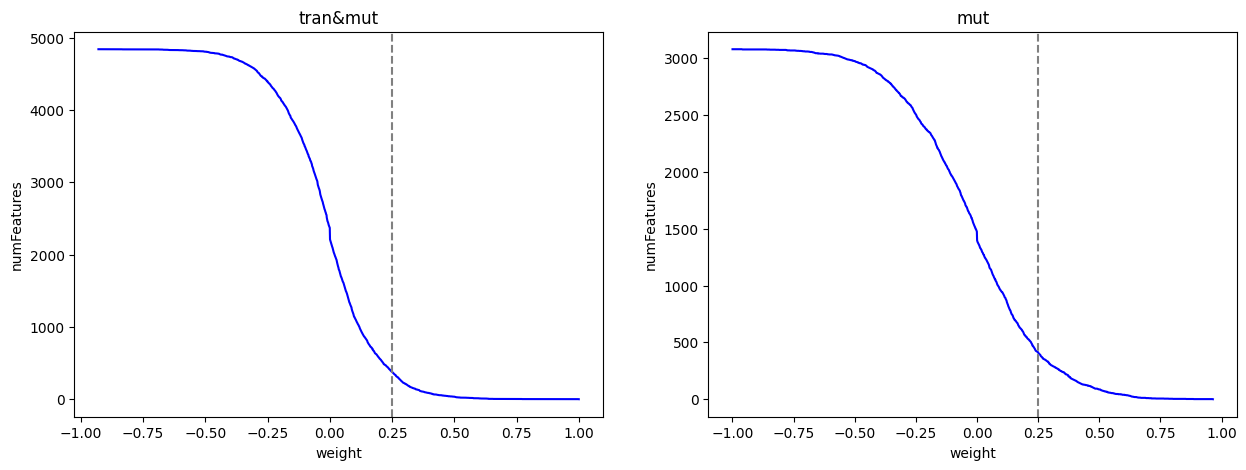

In [52]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax = ax.flatten()

ax[0].plot(plot_tm['weight'], plot_tm['numFeatures'], color='blue')
ax[0].axvline(x=0.25, color='grey', linestyle='--')
# ax[0].axvline(x=-0.25, color='grey', linestyle=':')
ax[0].set_xlabel('weight')
ax[0].set_ylabel('numFeatures')
ax[0].set_title('tran&mut')

ax[1].plot(plot_m['weight'], plot_m['numFeatures'], color='blue')
ax[1].axvline(x=0.25, color='grey', linestyle='--')
# ax[1].axvline(x=-0.40, color='grey', linestyle=':')
ax[1].set_xlabel('weight')
ax[1].set_ylabel('numFeatures')
ax[1].set_title('mut')

In [53]:
RAS_sF_tm = set(weights_tm.loc[weights_tm['weight'] > 0.25, 'feature'])
RAS_sF_tm = set([
    f for f in RAS_sF_tm 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])

RAS_sF_m = set(weights_m.loc[weights_m['weight'] > 0.25, 'feature'])

In [54]:
len(RAS_sF_tm), len(RAS_sF_m), len(RAS_sF_tm & RAS_sF_m)

(174, 411, 83)

In [55]:
weights[weights['feature'].isin(RAS_sF_tm & RAS_sF_m)]

,feature,gene,weight_tm,weight_m,sum
13,SNAP91_noCluster,SNAP91,0.506722,0.764458,0.705359
54,CRP_noCluster,CRP,0.374377,0.854985,0.682155
3,TFRC_noCluster,TFRC,0.613984,0.576537,0.660602
36,NDRG2_noCluster,NDRG2,0.411625,0.713354,0.624235
4,RAMP3_45222982_45222997,RAMP3,0.599358,0.494393,0.606907
...,...,...,...,...,...
118,FRMPD4_12734760_12734767,FRMPD4,0.289676,0.259514,0.304738
122,FRMD4A_13735926_13735926,FRMD4A,0.287476,0.260540,0.304086
127,MINK1_noCluster,MINK1,0.285561,0.252289,0.298445
142,MED6_noCluster,MED6,0.275039,0.260552,0.297191


In [56]:
# remove suffic _noCluster and _\d+_\d+
RAS_sG_tm = set([re.sub(r'_noCluster|_\d+_\d+', '', f) for f in RAS_sF_tm])
RAS_sG_m = set([re.sub(r'_noCluster|_\d+_\d+', '', f) for f in RAS_sF_m])

In [57]:
len(RAS_sG_tm), len(RAS_sG_m), len(RAS_sG_tm & RAS_sG_m)

(172, 408, 87)

In [58]:
weights[weights['gene'].isin(RAS_sG_tm & RAS_sG_m)]

,feature,gene,weight_tm,weight_m,sum
13,SNAP91_noCluster,SNAP91,0.506722,7.644578e-01,0.705359
54,CRP_noCluster,CRP,0.374377,8.549851e-01,0.682155
3,TFRC_noCluster,TFRC,0.613984,5.765367e-01,0.660602
36,NDRG2_noCluster,NDRG2,0.411625,7.133544e-01,0.624235
4,RAMP3_45222982_45222997,RAMP3,0.599358,4.943934e-01,0.606907
...,...,...,...,...,...
1673,RAMP3_noCluster,RAMP3,-0.039252,7.727824e-17,-0.021781
2459,KIRREL3_noCluster,KIRREL3,-0.212510,-4.261494e-02,-0.141565
2716,ACTL6B_noCluster,ACTL6B,-0.363734,-1.708852e-01,-0.296652
2519,SLC26A11_noCluster,SLC26A11,-0.237703,-3.477189e-01,-0.324842


In [59]:
'TNFSF11' in (RAS_sG_tm & RAS_sG_m)
weights[weights['gene'] == 'TNFSF11']

,feature,gene,weight_tm,weight_m,sum
46,TNFSF11_noCluster,TNFSF11,0.381889,0.366022,0.415005


In [60]:
RAS_sC_tm = set([
    f for f in RAS_sF_tm 
    if ('_noCluster' not in f)
])

RAS_sC_m = set([
    f for f in RAS_sF_m 
    if ('_noCluster' not in f)
])

In [61]:
len(RAS_sC_tm), len(RAS_sC_m), len(RAS_sC_tm & RAS_sC_m)

(24, 59, 14)

In [62]:
weights[weights['feature'].isin(RAS_sC_tm & RAS_sC_m)]

,feature,gene,weight_tm,weight_m,sum
4,RAMP3_45222982_45222997,RAMP3,0.599358,0.494393,0.606907
1,EML5_89124580_89124582,EML5,0.633787,0.360253,0.551578
39,ZNF7_146054902_146054916,ZNF7,0.408889,0.511631,0.510783
7,COPS4_83984313_83984315,COPS4,0.576807,0.340018,0.508732
38,KIRREL3_126333180_126333195,KIRREL3,0.408889,0.504953,0.507077
65,SIM1_100841571_100841583,SIM1,0.359217,0.533196,0.495187
11,ATAD5_29161567_29161578,ATAD5,0.520521,0.296001,0.453076
85,SLC26A11_78223063_78223063,SLC26A11,0.319648,0.460168,0.432708
34,SLC6A2_55729219_55729245,SLC6A2,0.412383,0.338057,0.416408
160,CNGA3_99013312_99013338,CNGA3,0.258384,0.356612,0.341252


Text(0.5, 1.0, 'Clusters')

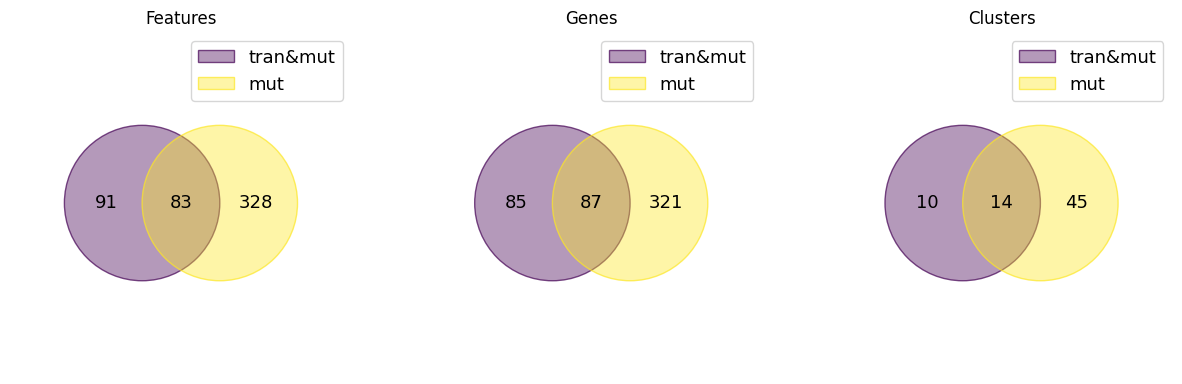

In [63]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

venn({
    'tran&mut': RAS_sF_tm,
    'mut': RAS_sF_m
}, ax=ax[0])
ax[0].set_title('Features')

venn({
    'tran&mut': RAS_sG_tm,
    'mut': RAS_sG_m
}, ax=ax[1])
ax[1].set_title('Genes')

venn({
    'tran&mut': RAS_sC_tm,
    'mut': RAS_sC_m
}, ax=ax[2])
ax[2].set_title('Clusters')

### logistic regression - oncodriveclustl

In [64]:
model_tm = joblib.load(f'{modelsDir_tm}/[\"{key}\"]/logisticRegression.joblib')
model_m = joblib.load(f'{modelsDir_m}/[\"{key}\"]/logisticRegression.joblib')

In [65]:
weights_tm = pd.DataFrame({'feature': feature_tm, 'weight': model_tm.coef_[0]}).sort_values('weight', ascending=False)
weights_m = pd.DataFrame({'feature': feature_m, 'weight': model_m.coef_[0]}).sort_values('weight', ascending=False)

weights_tm['gene'] = weights_tm['feature'].str.split('_').str[0]
weights_m['gene'] = weights_m['feature'].str.split('_').str[0]

weights_tm = weights_tm[['feature', 'gene', 'weight']]
weights_m = weights_m[['feature', 'gene', 'weight']]

# Normalize weights
weights_tm[['weight']] = weights_tm[['weight']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
weights_m[['weight']] = weights_m[['weight']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)

weights = pd.merge(weights_tm, weights_m, on=['feature', 'gene'], suffixes=('_tm', '_m'), how='inner')
weights['sum'] = weights['weight_tm'] + weights['weight_m']
weights[['sum']] = weights[['sum']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
weights = weights.sort_values('sum', ascending=False)

In [66]:
weights[(weights['weight_tm'] > 0) != (weights['weight_m'] > 0)]

,feature,gene,weight_tm,weight_m,sum
1583,DES_noCluster,DES,-0.044567,0.628004,0.335171
1872,DCPS_noCluster,DCPS,-0.080865,0.663453,0.334684
1512,KDM5C_noCluster,KDM5C,-0.038233,0.598954,0.322121
2101,CUL2_noCluster,CUL2,-0.115324,0.655057,0.310064
2124,POLB_noCluster,POLB,-0.121064,0.657092,0.307936
...,...,...,...,...,...
1162,PUS1_noCluster,PUS1,0.003625,-0.477279,-0.272103
2793,KCNK2_noCluster,KCNK2,-0.511821,0.029386,-0.277148
772,ROBO4_noCluster,ROBO4,0.062591,-0.559821,-0.285647
989,PDE5A_noCluster,PDE5A,0.027945,-0.599432,-0.328306


In [67]:
plot_tm = pd.DataFrame(
    [(i, len(weights_tm.loc[weights_tm['weight'] > i, 'feature'])) for i in np.arange(weights_tm['weight'].max(), weights_tm['weight'].min(), -0.001)],
    columns=['weight', 'numFeatures']
)
plot_m = pd.DataFrame(
    [(i, len(weights_m.loc[weights_m['weight'] > i, 'feature'])) for i in np.arange(weights_m['weight'].max(), weights_m['weight'].min(), -0.001)],
    columns=['weight', 'numFeatures']
)

Text(0.5, 1.0, 'mut')

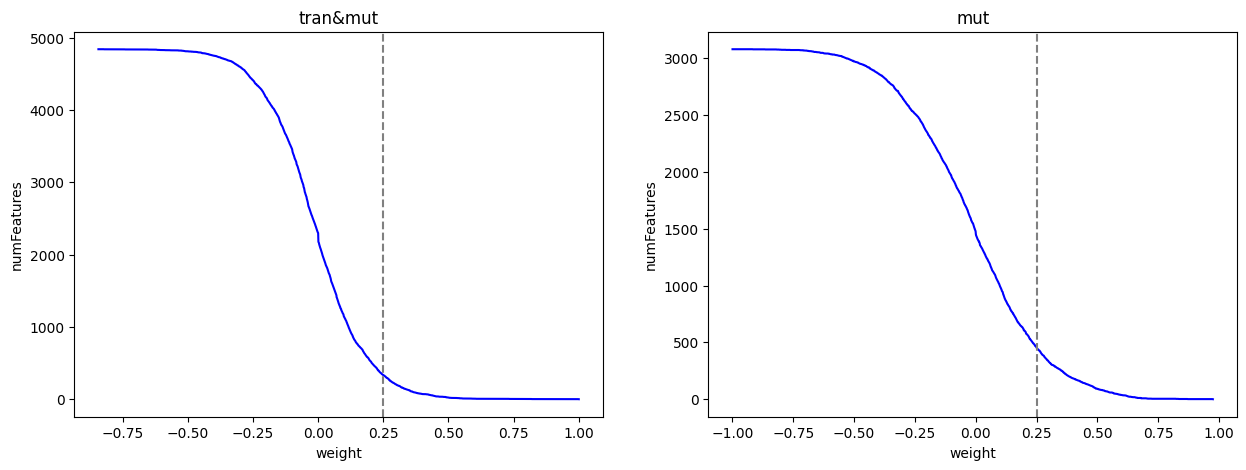

In [68]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax = ax.flatten()

ax[0].plot(plot_tm['weight'], plot_tm['numFeatures'], color='blue')
ax[0].axvline(x=0.25, color='grey', linestyle='--')
# ax[0].axvline(x=-0.25, color='grey', linestyle=':')
ax[0].set_xlabel('weight')
ax[0].set_ylabel('numFeatures')
ax[0].set_title('tran&mut')

ax[1].plot(plot_m['weight'], plot_m['numFeatures'], color='blue')
ax[1].axvline(x=0.25, color='grey', linestyle='--')
# ax[1].axvline(x=-0.40, color='grey', linestyle=':')
ax[1].set_xlabel('weight')
ax[1].set_ylabel('numFeatures')
ax[1].set_title('mut')

In [69]:
RAS_sF_tm = set(weights_tm.loc[weights_tm['weight'] > 0.25, 'feature'])
RAS_sF_tm = set([
    f for f in RAS_sF_tm 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])

RAS_sF_m = set(weights_m.loc[weights_m['weight'] > 0.25, 'feature'])

In [70]:
len(RAS_sF_tm), len(RAS_sF_m), len(RAS_sF_tm & RAS_sF_m)

(139, 455, 68)

In [71]:
weights[weights['feature'].isin(RAS_sF_tm & RAS_sF_m)]

,feature,gene,weight_tm,weight_m,sum
8,PDZD4_noCluster,PDZD4,0.491156,0.974620,0.842054
0,TFRC_noCluster,TFRC,1.000000,0.464858,0.841527
15,SNAP91_noCluster,SNAP91,0.456284,0.834364,0.741447
36,CRP_noCluster,CRP,0.377790,0.870917,0.717353
10,RAMP3_45222982_45222997,RAMP3,0.489467,0.547606,0.595775
...,...,...,...,...,...
133,MAGEB2_noCluster,MAGEB2,0.255631,0.324997,0.333557
120,CSH1_noCluster,CSH1,0.267142,0.308753,0.330839
86,ATAD3B_1421550_1421551,ATAD3B,0.301527,0.270493,0.328612
119,MINK1_noCluster,MINK1,0.267522,0.296490,0.324012


In [72]:
# remove suffic _noCluster and _\d+_\d+
RAS_sG_tm = set([re.sub(r'_noCluster|_\d+_\d+', '', f) for f in RAS_sF_tm])
RAS_sG_m = set([re.sub(r'_noCluster|_\d+_\d+', '', f) for f in RAS_sF_m])

In [73]:
len(RAS_sG_tm), len(RAS_sG_m), len(RAS_sG_tm & RAS_sG_m)

(138, 449, 73)

In [74]:
weights[weights['gene'].isin(RAS_sG_tm & RAS_sG_m)]

,feature,gene,weight_tm,weight_m,sum
8,PDZD4_noCluster,PDZD4,0.491156,0.974620,0.842054
0,TFRC_noCluster,TFRC,1.000000,0.464858,0.841527
15,SNAP91_noCluster,SNAP91,0.456284,0.834364,0.741447
36,CRP_noCluster,CRP,0.377790,0.870917,0.717353
10,RAMP3_45222982_45222997,RAMP3,0.489467,0.547606,0.595775
...,...,...,...,...,...
2166,ATAD3B_noCluster,ATAD3B,-0.129673,-0.000551,-0.074811
2463,KIRREL3_noCluster,KIRREL3,-0.208071,-0.103707,-0.179110
2580,SLC26A11_noCluster,SLC26A11,-0.256773,-0.335136,-0.340038
2760,NCOA5_44699131_44699153,NCOA5,-0.401006,-0.216733,-0.354877


In [75]:
'TNFSF11' in (RAS_sG_tm & RAS_sG_m)
weights[weights['gene'] == 'TNFSF11']

,feature,gene,weight_tm,weight_m,sum
43,TNFSF11_noCluster,TNFSF11,0.363912,0.472795,0.480669


In [76]:
RAS_sC_tm = set([
    f for f in RAS_sF_tm 
    if ('_noCluster' not in f)
])

RAS_sC_m = set([
    f for f in RAS_sF_m 
    if ('_noCluster' not in f)
])

In [77]:
len(RAS_sC_tm), len(RAS_sC_m), len(RAS_sC_tm & RAS_sC_m)

(22, 75, 11)

In [78]:
weights[weights['feature'].isin(RAS_sC_tm & RAS_sC_m)]

,feature,gene,weight_tm,weight_m,sum
10,RAMP3_45222982_45222997,RAMP3,0.489467,0.547606,0.595775
1,EML5_89124580_89124582,EML5,0.611318,0.348716,0.551517
58,SIM1_100841571_100841583,SIM1,0.333902,0.574148,0.521653
48,KIRREL3_126333180_126333195,KIRREL3,0.353687,0.546030,0.516867
5,COPS4_83984313_83984315,COPS4,0.542089,0.352478,0.513908
47,ZNF7_146054902_146054916,ZNF7,0.353687,0.503691,0.492544
14,ATAD5_29161567_29161578,ATAD5,0.461342,0.355618,0.469325
114,SLC26A11_78223063_78223063,SLC26A11,0.270753,0.422839,0.398453
35,SLC6A2_55729219_55729245,SLC6A2,0.383387,0.306747,0.396466
70,FRMPD4_12734760_12734767,FRMPD4,0.318562,0.281976,0.344996


Text(0.5, 1.0, 'Clusters')

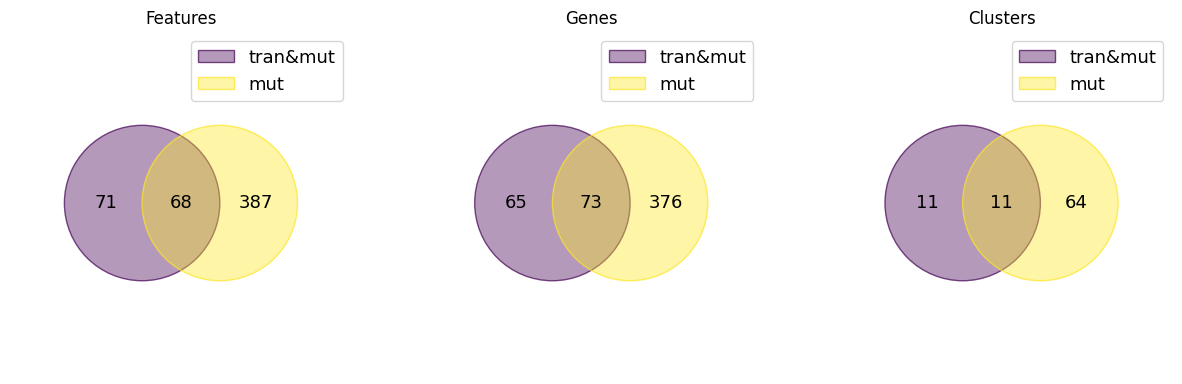

In [79]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

venn({
    'tran&mut': RAS_sF_tm,
    'mut': RAS_sF_m
}, ax=ax[0])
ax[0].set_title('Features')

venn({
    'tran&mut': RAS_sG_tm,
    'mut': RAS_sG_m
}, ax=ax[1])
ax[1].set_title('Genes')

venn({
    'tran&mut': RAS_sC_tm,
    'mut': RAS_sC_m
}, ax=ax[2])
ax[2].set_title('Clusters')

### logistic regression lasso - oncodriveclustl

In [80]:
model_tm = joblib.load(f'{modelsDir_tm}/[\"{key}\"]/logisticRegressionLasso.joblib')
model_m = joblib.load(f'{modelsDir_m}/[\"{key}\"]/logisticRegressionLasso.joblib')

In [81]:
weights_tm = pd.DataFrame({'feature': feature_tm, 'weight': model_tm.coef_[0]}).sort_values('weight', ascending=False)
weights_m = pd.DataFrame({'feature': feature_m, 'weight': model_m.coef_[0]}).sort_values('weight', ascending=False)

weights_tm['gene'] = weights_tm['feature'].str.split('_').str[0]
weights_m['gene'] = weights_m['feature'].str.split('_').str[0]

weights_tm = weights_tm[['feature', 'gene', 'weight']]
weights_m = weights_m[['feature', 'gene', 'weight']]

# Normalize weights
weights_tm[['weight']] = weights_tm[['weight']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
weights_m[['weight']] = weights_m[['weight']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)

weights = pd.merge(weights_tm, weights_m, on=['feature', 'gene'], suffixes=('_tm', '_m'), how='inner')
weights['sum'] = weights['weight_tm'] + weights['weight_m']
weights[['sum']] = weights[['sum']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
weights = weights.sort_values('sum', ascending=False)

In [82]:
weights[(weights['weight_tm'] > 0) != (weights['weight_m'] > 0)]

,feature,gene,weight_tm,weight_m,sum
0,TFRC_noCluster,TFRC,0.839077,NaN,NaN
1,GPR39_noCluster,GPR39,0.637235,NaN,NaN
2,IL10RA_noCluster,IL10RA,0.556386,NaN,NaN
3,NLRP12_noCluster,NLRP12,0.549807,NaN,NaN
4,DGKG_noCluster,DGKG,0.541568,NaN,NaN
...,...,...,...,...,...
257,E2F5_noCluster,E2F5,0.002913,NaN,NaN
258,DNASE1_noCluster,DNASE1,0.002901,NaN,NaN
259,SLC22A2_noCluster,SLC22A2,0.001392,NaN,NaN
260,BCAT1_noCluster,BCAT1,0.001333,NaN,NaN


In [83]:
sum(model_m.coef_[0])

0.0

model with only mutational data has all weights as zero

# maxmif HN S - onlyRAS_onlyNonRAS

In [84]:
key = 'maxmif HN S - onlyRAS_onlyNonRAS'

## mutclust

In [85]:
suffix_tm = 'TCGA_tran&mut_["mutclust - ALL"]'
modelsDir_tm = f'{data['ml___models']}optimized_accuracy/{suffix_tm}'
inputDir_tm = f'{data['ml___input']}{suffix_tm}'

suffix_m = 'merged_mut_["mutclust - ALL"]'
modelsDir_m = f'{data['ml___models']}optimized_accuracy/{suffix_m}'
inputDir_m = f'{data['ml___input']}{suffix_m}'

In [86]:
scaler_tm = joblib.load(f'{modelsDir_tm}/[\"{key}\"]/scaler.joblib')
scaler_m = joblib.load(f'{modelsDir_m}/[\"{key}\"]/scaler.joblib')

with open(f'{modelsDir_tm}/[\"{key}\"]/features_info.json') as f:
    feature_tm = json.load(f)['valid_features_train']
with open(f'{modelsDir_m}/[\"{key}\"]/features_info.json') as f:
    feature_m = json.load(f)['valid_features_train']

scaler_tm = joblib.load(f'{modelsDir_tm}/[\"{key}\"]/scaler.joblib')
scaler_m = joblib.load(f'{modelsDir_m}/[\"{key}\"]/scaler.joblib')

train_RAS_tm = pd.read_csv(f'{inputDir_tm}/train_RAS.csv', sep=',', comment='#', engine='python')
train_nonRAS_tm = pd.read_csv(f'{inputDir_tm}/train_nonRAS.csv', sep=',', comment='#', engine='python')
test_RAS_tm = pd.read_csv(f'{inputDir_tm}/test_RAS.csv', sep=',', comment='#', engine='python')
test_nonRAS_tm = pd.read_csv(f'{inputDir_tm}/test_nonRAS.csv', sep=',', comment='#', engine='python')

train_RAS_m = pd.read_csv(f'{inputDir_m}/train_RAS.csv', sep='\t', comment='#', engine='python')
train_nonRAS_m = pd.read_csv(f'{inputDir_m}/train_nonRAS.csv', sep='\t', comment='#', engine='python')
test_RAS_m = pd.read_csv(f'{inputDir_m}/test_RAS.csv', sep='\t', comment='#', engine='python')
test_nonRAS_m = pd.read_csv(f'{inputDir_m}/test_nonRAS.csv', sep='\t', comment='#', engine='python')

train_tm = scaler_tm.transform(pd.concat([train_RAS_tm, train_nonRAS_tm])[feature_tm])
test_tm = scaler_tm.transform(pd.concat([test_RAS_tm, test_nonRAS_tm])[feature_tm])

train_m = scaler_m.transform(pd.concat([train_RAS_m, train_nonRAS_m])[feature_m])
test_m = scaler_m.transform(pd.concat([test_RAS_m, test_nonRAS_m])[feature_m])

In [87]:
len(feature_tm), len(feature_m), len(set(feature_tm) & set(feature_m))

(7420, 4431, 4252)

### logistic regression - mutclust

In [88]:
model_tm = joblib.load(f'{modelsDir_tm}/[\"{key}\"]/logisticRegression.joblib')
model_m = joblib.load(f'{modelsDir_m}/[\"{key}\"]/logisticRegression.joblib')

In [89]:
weights_tm = pd.DataFrame({'feature': feature_tm, 'weight': model_tm.coef_[0]}).sort_values('weight', ascending=False)
weights_m = pd.DataFrame({'feature': feature_m, 'weight': model_m.coef_[0]}).sort_values('weight', ascending=False)

weights_tm['gene'] = weights_tm['feature'].str.split('_').str[0]
weights_m['gene'] = weights_m['feature'].str.split('_').str[0]

weights_tm = weights_tm[['feature', 'gene', 'weight']]
weights_m = weights_m[['feature', 'gene', 'weight']]

# Normalize weights
weights_tm[['weight']] = weights_tm[['weight']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
weights_m[['weight']] = weights_m[['weight']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)

weights = pd.merge(weights_tm, weights_m, on=['feature', 'gene'], suffixes=('_tm', '_m'), how='inner')
weights['sum'] = weights['weight_tm'] + weights['weight_m']
weights[['sum']] = weights[['sum']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
weights = weights.sort_values('sum', ascending=False)

In [90]:
weights[(weights['weight_tm'] > 0) != (weights['weight_m'] > 0)]

,feature,gene,weight_tm,weight_m,sum
2,HOXC8_noCluster,HOXC8,0.894161,-0.026255,0.566463
2654,CYP2C19_noCluster,CYP2C19,-0.076266,0.730277,0.426859
2047,CATSPER4_noCluster,CATSPER4,-0.013853,0.665476,0.425300
2148,HIST1H2BB_noCluster,HIST1H2BB,-0.027403,0.675482,0.422987
1828,PTS_noCluster,PTS,0.000000,0.636149,0.415201
...,...,...,...,...,...
1319,SLC25A22_noCluster,SLC25A22,0.050299,-0.564143,-0.335374
4220,GATA6_noCluster,GATA6,-0.543577,0.011993,-0.346953
1642,SLC30A9_noCluster,SLC30A9,0.018386,-0.564184,-0.356231
4240,SLC15A2_noCluster,SLC15A2,-0.638241,0.069124,-0.371450


In [91]:
plot_tm = pd.DataFrame(
    [(i, len(weights_tm.loc[weights_tm['weight'] > i, 'feature'])) for i in np.arange(weights_tm['weight'].max(), weights_tm['weight'].min(), -0.001)],
    columns=['weight', 'numFeatures']
)
plot_m = pd.DataFrame(
    [(i, len(weights_m.loc[weights_m['weight'] > i, 'feature'])) for i in np.arange(weights_m['weight'].max(), weights_m['weight'].min(), -0.001)],
    columns=['weight', 'numFeatures']
)

Text(0.5, 1.0, 'mut')

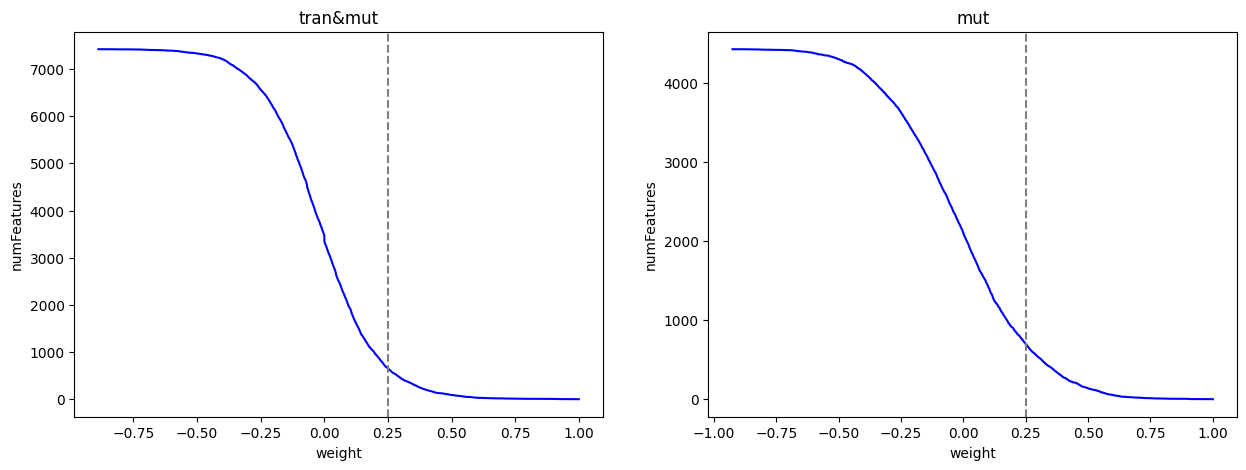

In [92]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax = ax.flatten()

ax[0].plot(plot_tm['weight'], plot_tm['numFeatures'], color='blue')
ax[0].axvline(x=0.25, color='grey', linestyle='--')
# ax[0].axvline(x=-0.25, color='grey', linestyle=':')
ax[0].set_xlabel('weight')
ax[0].set_ylabel('numFeatures')
ax[0].set_title('tran&mut')

ax[1].plot(plot_m['weight'], plot_m['numFeatures'], color='blue')
ax[1].axvline(x=0.25, color='grey', linestyle='--')
# ax[1].axvline(x=-0.40, color='grey', linestyle=':')
ax[1].set_xlabel('weight')
ax[1].set_ylabel('numFeatures')
ax[1].set_title('mut')

In [93]:
RAS_sF_tm = set(weights_tm.loc[weights_tm['weight'] > 0.25, 'feature'])
RAS_sF_tm = set([
    f for f in RAS_sF_tm 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])

RAS_sF_m = set(weights_m.loc[weights_m['weight'] > 0.25, 'feature'])

In [94]:
len(RAS_sF_tm), len(RAS_sF_m), len(RAS_sF_tm & RAS_sF_m)

(282, 697, 144)

In [95]:
weights[weights['feature'].isin(RAS_sF_tm & RAS_sF_m)]

,feature,gene,weight_tm,weight_m,sum
4,KERA_noCluster,KERA,0.762104,0.766329,0.997574
34,MACROD2_noCluster,MACROD2,0.504476,1.000000,0.981939
32,MAP3K2_noCluster,MAP3K2,0.516958,0.936804,0.948838
60,CRP_noCluster,CRP,0.443336,0.899463,0.876416
0,TFRC_noCluster,TFRC,0.978798,0.349112,0.866697
...,...,...,...,...,...
233,CHKA_noCluster,CHKA,0.273166,0.283501,0.363324
218,NEK4_noCluster,NEK4,0.288149,0.263345,0.359948
201,ACTL6B_45_50,ACTL6B,0.296303,0.253302,0.358715
209,SEC16B_noCluster,SEC16B,0.293725,0.254650,0.357912


In [96]:
# remove suffic _noCluster and _\d+_\d+
RAS_sG_tm = set([re.sub(r'_noCluster|_\d+_\d+', '', f) for f in RAS_sF_tm])
RAS_sG_m = set([re.sub(r'_noCluster|_\d+_\d+', '', f) for f in RAS_sF_m])

In [97]:
len(RAS_sG_tm), len(RAS_sG_m), len(RAS_sG_tm & RAS_sG_m)

(282, 691, 150)

In [98]:
weights[weights['gene'].isin(RAS_sG_tm & RAS_sG_m)]

,feature,gene,weight_tm,weight_m,sum
4,KERA_noCluster,KERA,0.762104,0.766329,0.997574
34,MACROD2_noCluster,MACROD2,0.504476,1.000000,0.981939
32,MAP3K2_noCluster,MAP3K2,0.516958,0.936804,0.948838
60,CRP_noCluster,CRP,0.443336,0.899463,0.876416
0,TFRC_noCluster,TFRC,0.978798,0.349112,0.866697
...,...,...,...,...,...
4103,NLRP4_284_288,NLRP4,-0.376513,-0.112868,-0.319408
4144,MACROD2_322_334,MACROD2,-0.397972,-0.096122,-0.322484
4048,OXSM_noCluster,OXSM,-0.349405,-0.267908,-0.402907
4178,ACTL6B_noCluster,ACTL6B,-0.436829,-0.388721,-0.538819


In [99]:
'TNFSF11' in (RAS_sG_tm & RAS_sG_m)
weights[weights['gene'] == 'TNFSF11']

,feature,gene,weight_tm,weight_m,sum
77,TNFSF11_noCluster,TNFSF11,0.42805,0.559948,0.644844


In [100]:
RAS_sC_tm = set([
    f for f in RAS_sF_tm 
    if ('_noCluster' not in f)
])

RAS_sC_m = set([
    f for f in RAS_sF_m 
    if ('_noCluster' not in f)
])

In [101]:
len(RAS_sC_tm), len(RAS_sC_m), len(RAS_sC_tm & RAS_sC_m)

(16, 40, 7)

In [102]:
weights[weights['feature'].isin(RAS_sC_tm & RAS_sC_m)]

,feature,gene,weight_tm,weight_m,sum
98,PCDHA3_537_619,PCDHA3,0.384922,0.560254,0.616896
14,NFKBIZ_191_212,NFKBIZ,0.586653,0.291816,0.573358
53,POM121_1021_1050,POM121,0.471342,0.401834,0.569903
71,RIMKLB_311_317,RIMKLB,0.433171,0.436607,0.567685
107,MIP_142_143,MIP,0.373929,0.383524,0.494373
208,OXSM_177_178,OXSM,0.294279,0.285432,0.378365
201,ACTL6B_45_50,ACTL6B,0.296303,0.253302,0.358715


Text(0.5, 1.0, 'Clusters')

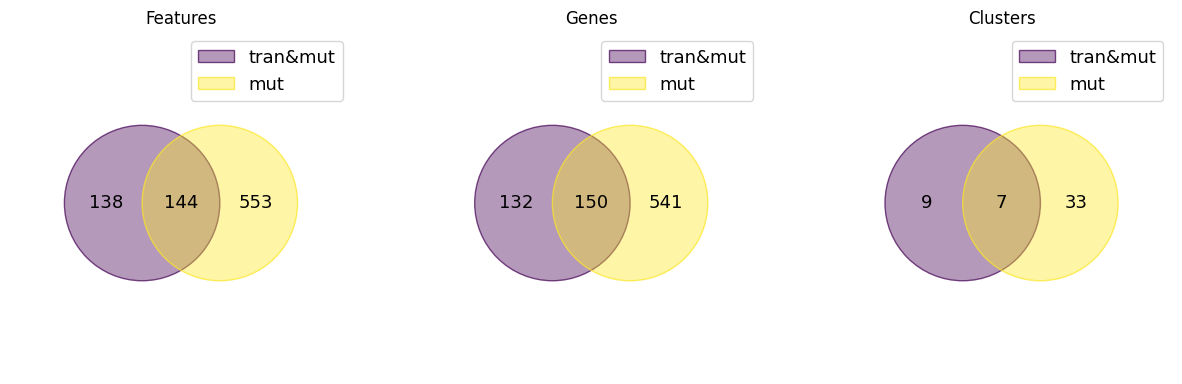

In [103]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

venn({
    'tran&mut': RAS_sF_tm,
    'mut': RAS_sF_m
}, ax=ax[0])
ax[0].set_title('Features')

venn({
    'tran&mut': RAS_sG_tm,
    'mut': RAS_sG_m
}, ax=ax[1])
ax[1].set_title('Genes')

venn({
    'tran&mut': RAS_sC_tm,
    'mut': RAS_sC_m
}, ax=ax[2])
ax[2].set_title('Clusters')

### random forest - mutclust

In [104]:
# model_tm = joblib.load(f'{modelsDir_tm}/[\"{key}\"]/randomForest.joblib')
# model_m = joblib.load(f'{modelsDir_m}/[\"{key}\"]/randomForest.joblib')

In [105]:
# shapValues = shap.KernelExplainer(model_tm.predict, shap.sample(train_tm, 10, random_state=int(data['seed']))).shap_values(test_tm)
# adjustment = model_tm.predict(test_tm)
# adjustment[adjustment == 0] = -1
# adjustment = np.tile(adjustment, (shapValues.shape[1], 1)).T
# adjusted_shapValues = shapValues * adjustment
# weights_tm = pd.DataFrame({'feature': feature_tm, 'weight': np.mean(adjusted_shapValues, axis=0)}).sort_values('weight', ascending=False)

# shapValues = shap.KernelExplainer(model_m.predict, shap.sample(train_m, 10, random_state=int(data['seed']))).shap_values(test_m)
# adjustment = model_m.predict(test_m)
# adjustment[adjustment == 0] = -1
# adjustment = np.tile(adjustment, (shapValues.shape[1], 1)).T
# adjusted_shapValues = shapValues * adjustment
# weights_m = pd.DataFrame({'feature': feature_m, 'weight': np.mean(adjusted_shapValues, axis=0)}).sort_values('weight', ascending=False)

# weights_tm['gene'] = weights_tm['feature'].str.split('_').str[0]
# weights_m['gene'] = weights_m['feature'].str.split('_').str[0]

# weights_tm = weights_tm[['feature', 'gene', 'weight']]
# weights_m = weights_m[['feature', 'gene', 'weight']]

# # Normalize weights
# weights_tm[['weight']] = weights_tm[['weight']].apply(
#     lambda col: col / col.abs().max(),
#     axis=0
# )
# weights_m[['weight']] = weights_m[['weight']].apply(
#     lambda col: col / col.abs().max(),
#     axis=0
# )

# weights = pd.merge(weights_tm, weights_m, on=['feature', 'gene'], suffixes=('_tm', '_m'), how='inner')
# weights['sum'] = weights['weight_tm'] + weights['weight_m']
# weights[['sum']] = weights[['sum']].apply(
#     lambda col: col / col.abs().max(),
#     axis=0
# )
# weights = weights.sort_values('sum', ascending=False)

In [106]:
# weights[(weights['weight_tm'] > 0) != (weights['weight_m'] > 0)]

In [107]:
# plot_tm = pd.DataFrame(
#     [(i, len(weights_tm.loc[weights_tm['weight'] > i, 'feature'])) for i in np.arange(weights_tm['weight'].max(), weights_tm['weight'].min(), -0.001)],
#     columns=['weight', 'numFeatures']
# )
# plot_m = pd.DataFrame(
#     [(i, len(weights_m.loc[weights_m['weight'] > i, 'feature'])) for i in np.arange(weights_m['weight'].max(), weights_m['weight'].min(), -0.001)],
#     columns=['weight', 'numFeatures']
# )

In [108]:
# fig, ax = plt.subplots(1, 2, figsize=(15, 5))
# ax = ax.flatten()

# ax[0].plot(plot_tm['weight'], plot_tm['numFeatures'], color='blue')
# ax[0].axvline(x=0.25, color='grey', linestyle='--')
# # ax[0].axvline(x=-0.25, color='grey', linestyle=':')
# ax[0].set_xlabel('weight')
# ax[0].set_ylabel('numFeatures')
# ax[0].set_title('tran&mut')

# ax[1].plot(plot_m['weight'], plot_m['numFeatures'], color='blue')
# ax[1].axvline(x=0.25, color='grey', linestyle='--')
# # ax[1].axvline(x=-0.40, color='grey', linestyle=':')
# ax[1].set_xlabel('weight')
# ax[1].set_ylabel('numFeatures')
# ax[1].set_title('mut')

In [109]:
# RAS_sF_tm = set(weights_tm.loc[weights_tm['weight'] > 0.25, 'feature'])
# RAS_sF_tm = set([
#     f for f in RAS_sF_tm 
#     if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
# ])

# RAS_sF_m = set(weights_m.loc[weights_m['weight'] > 0.25, 'feature'])

In [110]:
# len(RAS_sF_tm), len(RAS_sF_m), len(RAS_sF_tm & RAS_sF_m)

In [111]:
# weights[weights['feature'].isin(RAS_sF_tm & RAS_sF_m)]

In [112]:
# # remove suffic _noCluster and _\d+_\d+
# RAS_sG_tm = set([re.sub(r'_noCluster|_\d+_\d+', '', f) for f in RAS_sF_tm])
# RAS_sG_m = set([re.sub(r'_noCluster|_\d+_\d+', '', f) for f in RAS_sF_m])

In [113]:
# len(RAS_sG_tm), len(RAS_sG_m), len(RAS_sG_tm & RAS_sG_m)

In [114]:
# weights[weights['gene'].isin(RAS_sG_tm & RAS_sG_m)]

In [115]:
# 'TNFSF11' in (RAS_sG_tm & RAS_sG_m)
# weights[weights['gene'] == 'TNFSF11']

In [116]:
# RAS_sC_tm = set([
#     f for f in RAS_sF_tm 
#     if ('_noCluster' not in f)
# ])

# RAS_sC_m = set([
#     f for f in RAS_sF_m 
#     if ('_noCluster' not in f)
# ])

In [117]:
# len(RAS_sC_tm), len(RAS_sC_m), len(RAS_sC_tm & RAS_sC_m)

In [118]:
# weights[weights['feature'].isin(RAS_sC_tm & RAS_sC_m)]

### logistic regression lasso - mutclust

In [119]:
model_tm = joblib.load(f'{modelsDir_tm}/[\"{key}\"]/logisticRegressionLasso.joblib')
model_m = joblib.load(f'{modelsDir_m}/[\"{key}\"]/logisticRegressionLasso.joblib')

In [120]:
weights_tm = pd.DataFrame({'feature': feature_tm, 'weight': model_tm.coef_[0]}).sort_values('weight', ascending=False)
weights_m = pd.DataFrame({'feature': feature_m, 'weight': model_m.coef_[0]}).sort_values('weight', ascending=False)

weights_tm['gene'] = weights_tm['feature'].str.split('_').str[0]
weights_m['gene'] = weights_m['feature'].str.split('_').str[0]

weights_tm = weights_tm[['feature', 'gene', 'weight']]
weights_m = weights_m[['feature', 'gene', 'weight']]

# Normalize weights
weights_tm[['weight']] = weights_tm[['weight']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
weights_m[['weight']] = weights_m[['weight']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)

weights = pd.merge(weights_tm, weights_m, on=['feature', 'gene'], suffixes=('_tm', '_m'), how='inner')
weights['sum'] = weights['weight_tm'] + weights['weight_m']
weights[['sum']] = weights[['sum']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
weights = weights.sort_values('sum', ascending=False)

In [121]:
weights[(weights['weight_tm'] > 0) != (weights['weight_m'] > 0)]

,feature,gene,weight_tm,weight_m,sum
0,PLEKHG3_noCluster,PLEKHG3,0.601980,NaN,NaN
1,MOV10L1_noCluster,MOV10L1,0.561273,NaN,NaN
2,RAB3IL1_noCluster,RAB3IL1,0.510013,NaN,NaN
3,GIGYF2_241_272,GIGYF2,0.463222,NaN,NaN
4,COPS4_267_268,COPS4,0.443136,NaN,NaN
...,...,...,...,...,...
1622,SUPT16H_noCluster,SUPT16H,0.000140,NaN,NaN
1623,TYW1_noCluster,TYW1,0.000096,NaN,NaN
1624,NLRP6_noCluster,NLRP6,0.000089,NaN,NaN
1625,RASD2_noCluster,RASD2,0.000032,NaN,NaN


In [122]:
sum(model_m.coef_[0])

0.0

model with only mutational data has all weights as zero

## oncodriveclustl

In [123]:
suffix_tm = 'TCGA_tran&mut_["oncodriveclustl_coadreadParams - ALL"]'
modelsDir_tm = f'{data['ml___models']}optimized_accuracy/{suffix_tm}'
inputDir_tm = f'{data['ml___input']}{suffix_tm}'

suffix_m = 'merged_mut_["oncodriveclustl_coadreadParams - ALL"]'
modelsDir_m = f'{data['ml___models']}optimized_accuracy/{suffix_m}'
inputDir_m = f'{data['ml___input']}{suffix_m}'

In [124]:
scaler_tm = joblib.load(f'{modelsDir_tm}/[\"{key}\"]/scaler.joblib')
scaler_m = joblib.load(f'{modelsDir_m}/[\"{key}\"]/scaler.joblib')

with open(f'{modelsDir_tm}/[\"{key}\"]/features_info.json') as f:
    feature_tm = json.load(f)['valid_features_train']
with open(f'{modelsDir_m}/[\"{key}\"]/features_info.json') as f:
    feature_m = json.load(f)['valid_features_train']

scaler_tm = joblib.load(f'{modelsDir_tm}/[\"{key}\"]/scaler.joblib')
scaler_m = joblib.load(f'{modelsDir_m}/[\"{key}\"]/scaler.joblib')

train_RAS_tm = pd.read_csv(f'{inputDir_tm}/train_RAS.csv', sep=',', comment='#', engine='python')
train_nonRAS_tm = pd.read_csv(f'{inputDir_tm}/train_nonRAS.csv', sep=',', comment='#', engine='python')
test_RAS_tm = pd.read_csv(f'{inputDir_tm}/test_RAS.csv', sep=',', comment='#', engine='python')
test_nonRAS_tm = pd.read_csv(f'{inputDir_tm}/test_nonRAS.csv', sep=',', comment='#', engine='python')

train_RAS_m = pd.read_csv(f'{inputDir_m}/train_RAS.csv', sep='\t', comment='#', engine='python').set_index('Sample')
train_nonRAS_m = pd.read_csv(f'{inputDir_m}/train_nonRAS.csv', sep='\t', comment='#', engine='python').set_index('Sample')
test_RAS_m = pd.read_csv(f'{inputDir_m}/test_RAS.csv', sep='\t', comment='#', engine='python').set_index('Sample')
test_nonRAS_m = pd.read_csv(f'{inputDir_m}/test_nonRAS.csv', sep='\t', comment='#', engine='python').set_index('Sample')

train_tm = scaler_tm.transform(pd.concat([train_RAS_tm, train_nonRAS_tm])[feature_tm])
test_tm = scaler_tm.transform(pd.concat([test_RAS_tm, test_nonRAS_tm])[feature_tm])

train_m = scaler_m.transform(pd.concat([train_RAS_m, train_nonRAS_m])[feature_m])
test_m = scaler_m.transform(pd.concat([test_RAS_m, test_nonRAS_m])[feature_m])

In [125]:
len(feature_tm), len(feature_m), len(set(feature_tm) & set(feature_m))

(7693, 4975, 4525)

### logistic regression - oncodriveclustl

In [126]:
model_tm = joblib.load(f'{modelsDir_tm}/[\"{key}\"]/logisticRegression.joblib')
model_m = joblib.load(f'{modelsDir_m}/[\"{key}\"]/logisticRegression.joblib')

In [127]:
weights_tm = pd.DataFrame({'feature': feature_tm, 'weight': model_tm.coef_[0]}).sort_values('weight', ascending=False)
weights_m = pd.DataFrame({'feature': feature_m, 'weight': model_m.coef_[0]}).sort_values('weight', ascending=False)

weights_tm['gene'] = weights_tm['feature'].str.split('_').str[0]
weights_m['gene'] = weights_m['feature'].str.split('_').str[0]

weights_tm = weights_tm[['feature', 'gene', 'weight']]
weights_m = weights_m[['feature', 'gene', 'weight']]

# Normalize weights
weights_tm[['weight']] = weights_tm[['weight']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
weights_m[['weight']] = weights_m[['weight']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)

weights = pd.merge(weights_tm, weights_m, on=['feature', 'gene'], suffixes=('_tm', '_m'), how='inner')
weights['sum'] = weights['weight_tm'] + weights['weight_m']
weights[['sum']] = weights[['sum']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
weights = weights.sort_values('sum', ascending=False)

In [128]:
weights[(weights['weight_tm'] > 0) != (weights['weight_m'] > 0)]

,feature,gene,weight_tm,weight_m,sum
2196,CATSPER4_noCluster,CATSPER4,-0.014158,0.742716,0.493318
2847,CYP2C19_noCluster,CYP2C19,-0.074277,0.669860,0.403278
2077,CD86_noCluster,CD86,-0.000057,0.594568,0.402553
11,ANKRD6_90337365_90337366,ANKRD6,0.615237,-0.028230,0.397472
2080,MAGED1_noCluster,MAGED1,-0.000289,0.582342,0.394117
...,...,...,...,...,...
4508,SLC15A2_noCluster,SLC15A2,-0.589085,0.142068,-0.302682
4475,PHOX2B_noCluster,PHOX2B,-0.484030,0.011832,-0.319733
4499,AIFM3_noCluster,AIFM3,-0.553419,0.026111,-0.357048
1778,MRVI1_noCluster,MRVI1,0.013896,-0.615966,-0.407671


In [129]:
plot_tm = pd.DataFrame(
    [(i, len(weights_tm.loc[weights_tm['weight'] > i, 'feature'])) for i in np.arange(weights_tm['weight'].max(), weights_tm['weight'].min(), -0.001)],
    columns=['weight', 'numFeatures']
)
plot_m = pd.DataFrame(
    [(i, len(weights_m.loc[weights_m['weight'] > i, 'feature'])) for i in np.arange(weights_m['weight'].max(), weights_m['weight'].min(), -0.001)],
    columns=['weight', 'numFeatures']
)

Text(0.5, 1.0, 'mut')

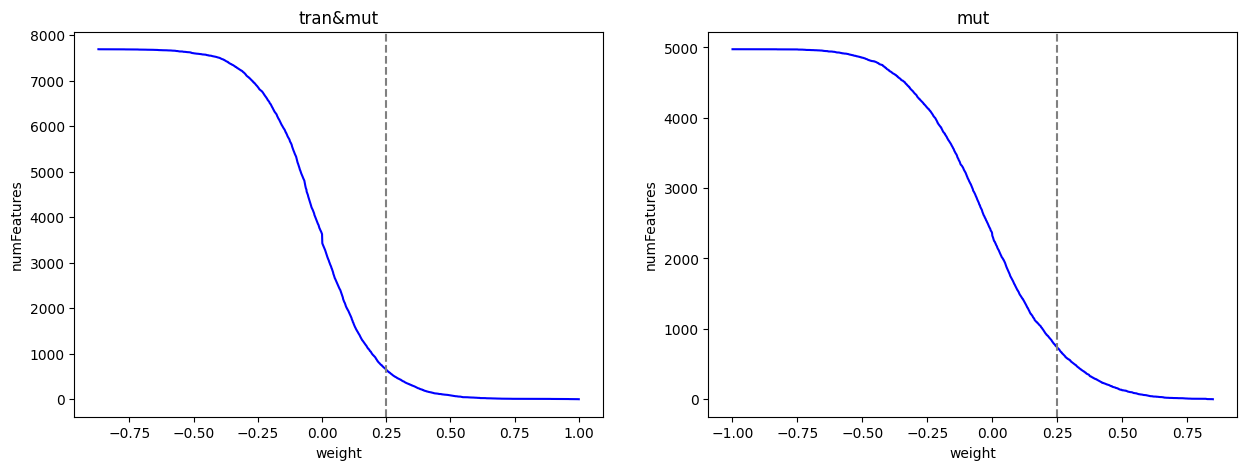

In [130]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax = ax.flatten()

ax[0].plot(plot_tm['weight'], plot_tm['numFeatures'], color='blue')
ax[0].axvline(x=0.25, color='grey', linestyle='--')
# ax[0].axvline(x=-0.25, color='grey', linestyle=':')
ax[0].set_xlabel('weight')
ax[0].set_ylabel('numFeatures')
ax[0].set_title('tran&mut')

ax[1].plot(plot_m['weight'], plot_m['numFeatures'], color='blue')
ax[1].axvline(x=0.25, color='grey', linestyle='--')
# ax[1].axvline(x=-0.40, color='grey', linestyle=':')
ax[1].set_xlabel('weight')
ax[1].set_ylabel('numFeatures')
ax[1].set_title('mut')

In [131]:
RAS_sF_tm = set(weights_tm.loc[weights_tm['weight'] > 0.25, 'feature'])
RAS_sF_tm = set([
    f for f in RAS_sF_tm 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])

RAS_sF_m = set(weights_m.loc[weights_m['weight'] > 0.25, 'feature'])

In [132]:
len(RAS_sF_tm), len(RAS_sF_m), len(RAS_sF_tm & RAS_sF_m)

(290, 734, 151)

In [133]:
weights[weights['feature'].isin(RAS_sF_tm & RAS_sF_m)]

,feature,gene,weight_tm,weight_m,sum
37,MAP3K2_noCluster,MAP3K2,0.490895,0.849564,0.907646
4,KERA_noCluster,KERA,0.679006,0.658061,0.905349
58,CRP_noCluster,CRP,0.443726,0.845476,0.872939
35,DUSP10_noCluster,DUSP10,0.495135,0.750243,0.843265
75,TAS1R2_noCluster,TAS1R2,0.419404,0.825707,0.843084
...,...,...,...,...,...
281,GTPBP6_noCluster,GTPBP6,0.253538,0.310234,0.381739
272,MCM9_noCluster,MCM9,0.255265,0.307087,0.380778
247,FBXO44_noCluster,FBXO44,0.268232,0.290643,0.378424
208,MINK1_noCluster,MINK1,0.295978,0.259243,0.375949


In [134]:
# remove suffic _noCluster and _\d+_\d+
RAS_sG_tm = set([re.sub(r'_noCluster|_\d+_\d+', '', f) for f in RAS_sF_tm])
RAS_sG_m = set([re.sub(r'_noCluster|_\d+_\d+', '', f) for f in RAS_sF_m])

In [135]:
len(RAS_sG_tm), len(RAS_sG_m), len(RAS_sG_tm & RAS_sG_m)

(287, 717, 158)

In [136]:
weights[weights['gene'].isin(RAS_sG_tm & RAS_sG_m)]

,feature,gene,weight_tm,weight_m,sum
37,MAP3K2_noCluster,MAP3K2,0.490895,0.849564,0.907646
4,KERA_noCluster,KERA,0.679006,0.658061,0.905349
58,CRP_noCluster,CRP,0.443726,0.845476,0.872939
35,DUSP10_noCluster,DUSP10,0.495135,0.750243,0.843265
75,TAS1R2_noCluster,TAS1R2,0.419404,0.825707,0.843084
...,...,...,...,...,...
4138,PCDHA3_140182288_140182324,PCDHA3,-0.274940,-0.397449,-0.455285
4356,SLC26A11_noCluster,SLC26A11,-0.356846,-0.355991,-0.482674
4462,NCOA5_44699131_44699153,NCOA5,-0.451309,-0.289502,-0.501615
4426,SLC6A2_noCluster,SLC6A2,-0.395310,-0.599164,-0.673374


In [137]:
'TNFSF11' in (RAS_sG_tm & RAS_sG_m)
weights[weights['gene'] == 'TNFSF11']

,feature,gene,weight_tm,weight_m,sum
98,TNFSF11_noCluster,TNFSF11,0.389467,0.540787,0.629889


In [138]:
RAS_sC_tm = set([
    f for f in RAS_sF_tm 
    if ('_noCluster' not in f)
])

RAS_sC_m = set([
    f for f in RAS_sF_m 
    if ('_noCluster' not in f)
])

In [139]:
len(RAS_sC_tm), len(RAS_sC_m), len(RAS_sC_tm & RAS_sC_m)

(41, 129, 25)

In [140]:
weights[weights['feature'].isin(RAS_sC_tm & RAS_sC_m)]

,feature,gene,weight_tm,weight_m,sum
0,NYAP2_226447504_226447522,NYAP2,0.981995,0.252349,0.835794
89,SIM1_100841571_100841583,SIM1,0.399554,0.696176,0.741936
32,RAMP3_45222982_45222997,RAMP3,0.504613,0.549129,0.713505
112,SLC23A2_4883156_4883156,SLC23A2,0.372036,0.613969,0.667640
12,EML5_89124580_89124582,EML5,0.615237,0.326838,0.637894
14,MARK4_45783968_45783975,MARK4,0.605162,0.333729,0.635738
279,HAO1_7894923_7894923,HAO1,0.253821,0.650742,0.612494
155,PPP2R5E_64006394_64006397,PPP2R5E,0.331570,0.554584,0.600029
138,CYP17A1_104592810_104592814,CYP17A1,0.348349,0.533879,0.597370
29,COPS4_83984313_83984315,COPS4,0.513411,0.365954,0.595432


Text(0.5, 1.0, 'Clusters')

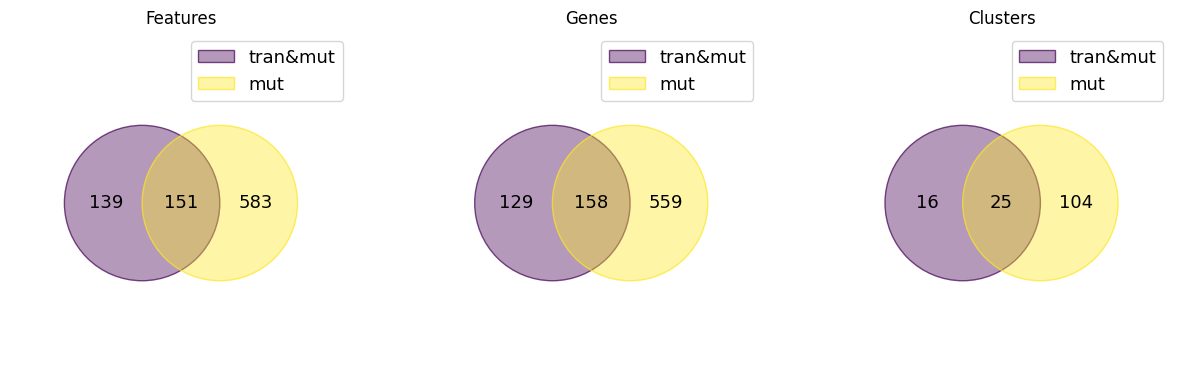

In [141]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

venn({
    'tran&mut': RAS_sF_tm,
    'mut': RAS_sF_m
}, ax=ax[0])
ax[0].set_title('Features')

venn({
    'tran&mut': RAS_sG_tm,
    'mut': RAS_sG_m
}, ax=ax[1])
ax[1].set_title('Genes')

venn({
    'tran&mut': RAS_sC_tm,
    'mut': RAS_sC_m
}, ax=ax[2])
ax[2].set_title('Clusters')

### linearSVM - oncodriveclustl

In [142]:
model_tm = joblib.load(f'{modelsDir_tm}/[\"{key}\"]/linearSVM.joblib')
model_m = joblib.load(f'{modelsDir_m}/[\"{key}\"]/linearSVM.joblib')

In [143]:
weights_tm = pd.DataFrame({'feature': feature_tm, 'weight': model_tm.coef_[0]}).sort_values('weight', ascending=False)
weights_m = pd.DataFrame({'feature': feature_m, 'weight': model_m.coef_[0]}).sort_values('weight', ascending=False)

weights_tm['gene'] = weights_tm['feature'].str.split('_').str[0]
weights_m['gene'] = weights_m['feature'].str.split('_').str[0]

weights_tm = weights_tm[['feature', 'gene', 'weight']]
weights_m = weights_m[['feature', 'gene', 'weight']]

# Normalize weights
weights_tm[['weight']] = weights_tm[['weight']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
weights_m[['weight']] = weights_m[['weight']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)

weights = pd.merge(weights_tm, weights_m, on=['feature', 'gene'], suffixes=('_tm', '_m'), how='inner')
weights['sum'] = weights['weight_tm'] + weights['weight_m']
weights[['sum']] = weights[['sum']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
weights = weights.sort_values('sum', ascending=False)

In [144]:
weights[(weights['weight_tm'] > 0) != (weights['weight_m'] > 0)]

,feature,gene,weight_tm,weight_m,sum
2424,CATSPER4_noCluster,CATSPER4,-2.433832e-02,0.779095,0.543042
2572,DES_noCluster,DES,-3.395168e-02,0.593584,0.402652
2138,KIF2B_51900722_51900745,KIF2B,0.000000e+00,0.547140,0.393663
14,ANKRD6_90337365_90337366,ANKRD6,5.569226e-01,-0.031122,0.378310
2103,PTS_noCluster,PTS,0.000000e+00,0.503394,0.362188
...,...,...,...,...,...
1933,HEMK1_noCluster,HEMK1,2.922793e-17,-0.450433,-0.324083
1695,P2RY8_noCluster,P2RY8,2.052002e-02,-0.481214,-0.331466
1860,TIMM44_noCluster,TIMM44,5.854454e-03,-0.485587,-0.345164
1958,LELP1_153177307_153177307,LELP1,4.871322e-18,-0.560208,-0.403065


In [145]:
plot_tm = pd.DataFrame(
    [(i, len(weights_tm.loc[weights_tm['weight'] > i, 'feature'])) for i in np.arange(weights_tm['weight'].max(), weights_tm['weight'].min(), -0.001)],
    columns=['weight', 'numFeatures']
)
plot_m = pd.DataFrame(
    [(i, len(weights_m.loc[weights_m['weight'] > i, 'feature'])) for i in np.arange(weights_m['weight'].max(), weights_m['weight'].min(), -0.001)],
    columns=['weight', 'numFeatures']
)

Text(0.5, 1.0, 'mut')

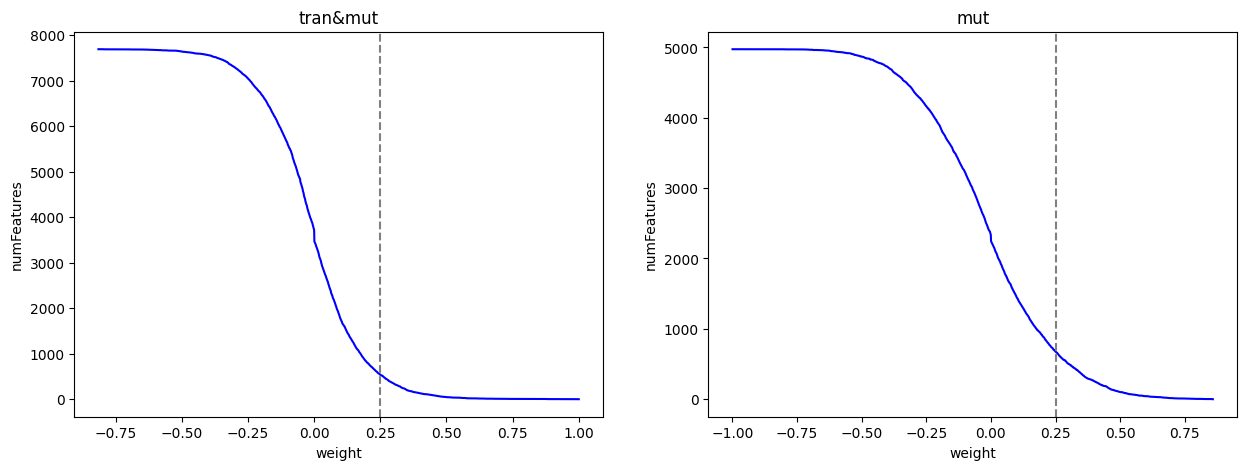

In [146]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax = ax.flatten()

ax[0].plot(plot_tm['weight'], plot_tm['numFeatures'], color='blue')
ax[0].axvline(x=0.25, color='grey', linestyle='--')
# ax[0].axvline(x=-0.25, color='grey', linestyle=':')
ax[0].set_xlabel('weight')
ax[0].set_ylabel('numFeatures')
ax[0].set_title('tran&mut')

ax[1].plot(plot_m['weight'], plot_m['numFeatures'], color='blue')
ax[1].axvline(x=0.25, color='grey', linestyle='--')
# ax[1].axvline(x=-0.40, color='grey', linestyle=':')
ax[1].set_xlabel('weight')
ax[1].set_ylabel('numFeatures')
ax[1].set_title('mut')

In [147]:
RAS_sF_tm = set(weights_tm.loc[weights_tm['weight'] > 0.25, 'feature'])
RAS_sF_tm = set([
    f for f in RAS_sF_tm 
    if ('_noCluster' in f or re.search(r'_\d+_\d+', f))
])

RAS_sF_m = set(weights_m.loc[weights_m['weight'] > 0.25, 'feature'])

In [148]:
len(RAS_sF_tm), len(RAS_sF_m), len(RAS_sF_tm & RAS_sF_m)

(260, 678, 132)

In [149]:
weights[weights['feature'].isin(RAS_sF_tm & RAS_sF_m)]

,feature,gene,weight_tm,weight_m,sum
5,KERA_noCluster,KERA,0.652596,0.640211,0.930166
1,TFRC_noCluster,TFRC,0.921629,0.361211,0.922994
0,NYAP2_226447504_226447522,NYAP2,1.000000,0.262479,0.908344
37,MAP3K2_noCluster,MAP3K2,0.464914,0.788970,0.902160
75,TAS1R2_noCluster,TAS1R2,0.387466,0.855800,0.894521
...,...,...,...,...,...
213,IDH3G_noCluster,IDH3G,0.274685,0.290676,0.406773
250,TBC1D17_noCluster,TBC1D17,0.258502,0.289186,0.394057
200,ATAD3B_1421550_1421551,ATAD3B,0.278811,0.268540,0.393815
194,NOMO1_noCluster,NOMO1,0.281118,0.263466,0.391824


In [150]:
# remove suffic _noCluster and _\d+_\d+
RAS_sG_tm = set([re.sub(r'_noCluster|_\d+_\d+', '', f) for f in RAS_sF_tm])
RAS_sG_m = set([re.sub(r'_noCluster|_\d+_\d+', '', f) for f in RAS_sF_m])

In [151]:
len(RAS_sG_tm), len(RAS_sG_m), len(RAS_sG_tm & RAS_sG_m)

(258, 659, 138)

In [152]:
weights[weights['gene'].isin(RAS_sG_tm & RAS_sG_m)]

,feature,gene,weight_tm,weight_m,sum
5,KERA_noCluster,KERA,0.652596,0.640211,0.930166
1,TFRC_noCluster,TFRC,0.921629,0.361211,0.922994
0,NYAP2_226447504_226447522,NYAP2,1.000000,0.262479,0.908344
37,MAP3K2_noCluster,MAP3K2,0.464914,0.788970,0.902160
75,TAS1R2_noCluster,TAS1R2,0.387466,0.855800,0.894521
...,...,...,...,...,...
4397,MARK4_noCluster,MARK4,-0.346324,-0.218023,-0.406043
4052,PCDHA3_140182288_140182324,PCDHA3,-0.229463,-0.341918,-0.411105
4328,NLRP4_56369571_56369635,NLRP4,-0.316288,-0.279936,-0.428978
4294,SLC26A11_noCluster,SLC26A11,-0.299011,-0.358504,-0.473078


In [153]:
'TNFSF11' in (RAS_sG_tm & RAS_sG_m)
weights[weights['gene'] == 'TNFSF11']

,feature,gene,weight_tm,weight_m,sum
99,TNFSF11_noCluster,TNFSF11,0.356869,0.462412,0.589467


In [154]:
RAS_sC_tm = set([
    f for f in RAS_sF_tm 
    if ('_noCluster' not in f)
])

RAS_sC_m = set([
    f for f in RAS_sF_m 
    if ('_noCluster' not in f)
])

In [155]:
len(RAS_sC_tm), len(RAS_sC_m), len(RAS_sC_tm & RAS_sC_m)

(38, 117, 23)

In [156]:
weights[weights['feature'].isin(RAS_sC_tm & RAS_sC_m)]

,feature,gene,weight_tm,weight_m,sum
0,NYAP2_226447504_226447522,NYAP2,1.000000,0.262479,0.908344
73,SIM1_100841571_100841583,SIM1,0.389175,0.707174,0.788816
19,RAMP3_45222982_45222997,RAMP3,0.505261,0.559422,0.766032
220,P2RY8_1584455_1584493,P2RY8,0.270743,0.670546,0.677251
111,SLC23A2_4883156_4883156,SLC23A2,0.349209,0.584946,0.672118
10,MARK4_45783968_45783975,MARK4,0.577157,0.347006,0.664929
159,PPP2R5E_64006394_64006397,PPP2R5E,0.305144,0.586281,0.641374
15,EML5_89124580_89124582,EML5,0.556923,0.278896,0.601366
87,KIRREL3_126333180_126333195,KIRREL3,0.370670,0.451088,0.591249
48,COPS4_83984313_83984315,COPS4,0.443961,0.361912,0.579820


Text(0.5, 1.0, 'Clusters')

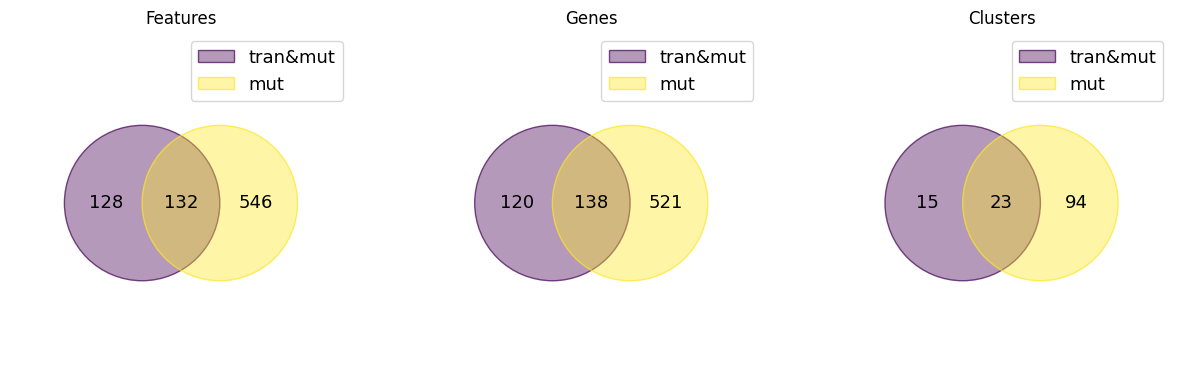

In [157]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

venn({
    'tran&mut': RAS_sF_tm,
    'mut': RAS_sF_m
}, ax=ax[0])
ax[0].set_title('Features')

venn({
    'tran&mut': RAS_sG_tm,
    'mut': RAS_sG_m
}, ax=ax[1])
ax[1].set_title('Genes')

venn({
    'tran&mut': RAS_sC_tm,
    'mut': RAS_sC_m
}, ax=ax[2])
ax[2].set_title('Clusters')

### logistic regression lasso - oncodriveclustl

In [158]:
model_tm = joblib.load(f'{modelsDir_tm}/[\"{key}\"]/logisticRegressionLasso.joblib')
model_m = joblib.load(f'{modelsDir_m}/[\"{key}\"]/logisticRegressionLasso.joblib')

In [159]:
weights_tm = pd.DataFrame({'feature': feature_tm, 'weight': model_tm.coef_[0]}).sort_values('weight', ascending=False)
weights_m = pd.DataFrame({'feature': feature_m, 'weight': model_m.coef_[0]}).sort_values('weight', ascending=False)

weights_tm['gene'] = weights_tm['feature'].str.split('_').str[0]
weights_m['gene'] = weights_m['feature'].str.split('_').str[0]

weights_tm = weights_tm[['feature', 'gene', 'weight']]
weights_m = weights_m[['feature', 'gene', 'weight']]

# Normalize weights
weights_tm[['weight']] = weights_tm[['weight']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
weights_m[['weight']] = weights_m[['weight']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)

weights = pd.merge(weights_tm, weights_m, on=['feature', 'gene'], suffixes=('_tm', '_m'), how='inner')
weights['sum'] = weights['weight_tm'] + weights['weight_m']
weights[['sum']] = weights[['sum']].apply(
    lambda col: col / col.abs().max(),
    axis=0
)
weights = weights.sort_values('sum', ascending=False)

In [160]:
weights[(weights['weight_tm'] > 0) != (weights['weight_m'] > 0)]

,feature,gene,weight_tm,weight_m,sum
0,NYAP2_226447504_226447522,NYAP2,0.629401,NaN,NaN
1,HOXC8_noCluster,HOXC8,0.501087,NaN,NaN
2,FGF1_noCluster,FGF1,0.495080,NaN,NaN
3,SAT1_noCluster,SAT1,0.486451,NaN,NaN
4,FGF11_noCluster,FGF11,0.442809,NaN,NaN
...,...,...,...,...,...
451,ZNF257_22271249_22271257,ZNF257,0.000810,NaN,NaN
452,RFC2_noCluster,RFC2,0.000620,NaN,NaN
453,NPBWR1_noCluster,NPBWR1,0.000578,NaN,NaN
454,LCT_noCluster,LCT,0.000497,NaN,NaN


In [161]:
sum(model_m.coef_[0])

0.0

model with only mutational data has all weights as zero